# zb08 w czerwonych filtrach: Ic, i, z

Flaty (`processed-ofp/flats/<filtr>/`) i niebo na klatkach z gwiazdami (`processed-ofp/science/`): surowa klatka minus
master zero oraz klatka po redukcji (`_zdf`). Niebo mierzymy medianą w blokach 16x16 px - mediana pomija gwiazdy, jeśli
pole nie jest gęste.

In [1]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import gaussian_filter

FLATS = "/data/fits/zb08/processed-ofp/flats"
SCIENCE = "/data/fits/zb08/processed-ofp/science"
BLOCK = 16   # rozmiar bloku do mediany nieba [px]


def blocks(d, b=BLOCK):
    # mediana w blokach b x b px -> mapa (2048/b) x (2048/b)
    n = d.shape[0] // b
    return np.nanmedian(d[:n * b, :n * b].reshape(n, b, n, b).transpose(0, 2, 1, 3).reshape(n, n, b * b), axis=2)


## 1. Flaty

Master flaty z nocy 1345, znormalizowane do mediany. Głębokość dysku = mediana w środku (r < 250 px od (950, 1000)) /
mediana w pierścieniu 450-600 px.

flat V: głębokość dysku 1.003


flat Ic: głębokość dysku 0.970


flat i: głębokość dysku 0.995


flat z: głębokość dysku 0.943


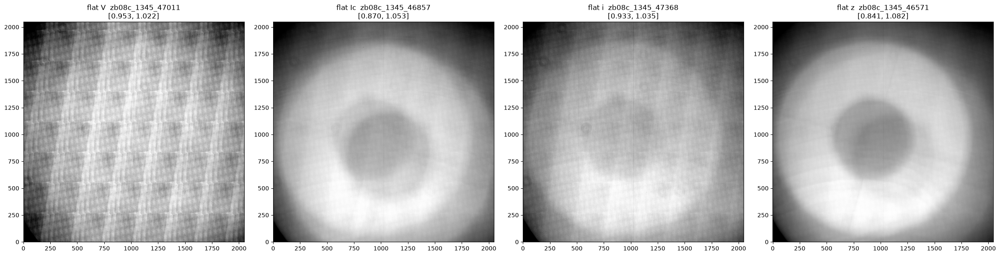

In [2]:
FLAT_LIST = [("V", "zb08c_1345_47011"), ("Ic", "zb08c_1345_46857"), ("i", "zb08c_1345_47368"), ("z", "zb08c_1345_46571")]
XC, YC = 950, 1000   # środek dysku [px]

yy, xx = np.mgrid[0:2048 // BLOCK, 0:2048 // BLOCK] * BLOCK + BLOCK / 2
r = np.hypot(xx - XC, yy - YC)
inner, ring = r < 250, (r > 450) & (r < 600)

fig, axes = plt.subplots(1, len(FLAT_LIST), figsize=(6 * len(FLAT_LIST), 6))
for ax, (flt, base) in zip(axes, FLAT_LIST):
    flat = fits.getdata(f"{FLATS}/{flt}/{base}/{base}_master_f_{flt}.fits").astype(np.float64)
    flat = flat / np.nanmedian(flat)
    m = blocks(flat)
    print(f"flat {flt}: głębokość dysku {np.median(m[inner]) / np.median(m[ring]):.3f}")
    lo, hi = np.nanpercentile(flat, [1, 99])
    ax.imshow(flat, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"flat {flt}  {base}\n[{lo:.3f}, {hi:.3f}]")
plt.tight_layout()
plt.show()


## 2. Niebo na klatkach z gwiazdami

Pole BK Tuc, noce 1342 i 1345, po 4 klatki na filtr (najdłuższe ekspozycje: z 90 s, Ic 36 s, i 20 s). Każda mapa
znormalizowana do swojej mediany, potem mediana z 4 klatek (gwiazdy w tych samych miejscach zostają, szum maleje).

Kolumny: flat użyty do redukcji | surowa klatka minus master zero | klatka po redukcji (`_zdf`).

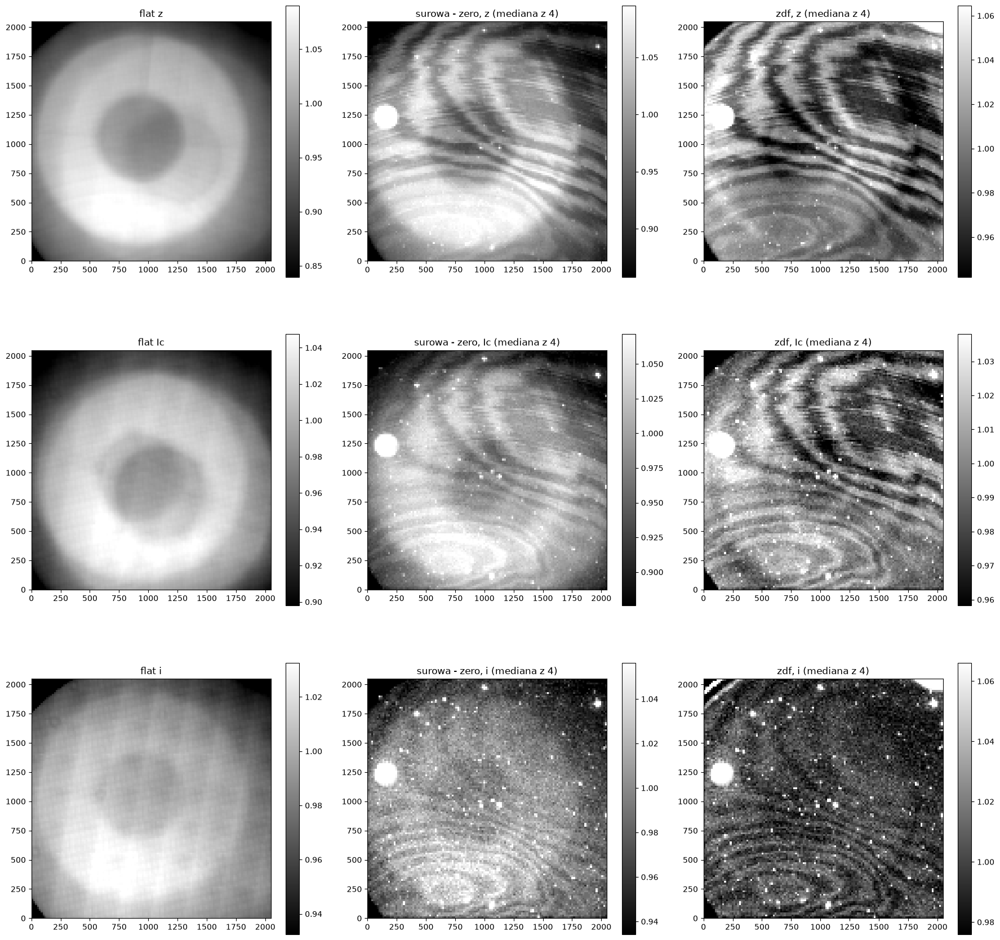

In [3]:
SETS = {
    "z": ["zb08c_1345_51952", "zb08c_1345_51840", "zb08c_1342_58934", "zb08c_1342_58823"],
    "Ic": ["zb08c_1345_51527", "zb08c_1345_51477", "zb08c_1342_58462", "zb08c_1342_58512"],
    "i": ["zb08c_1345_51771", "zb08c_1345_51803", "zb08c_1342_58757", "zb08c_1342_58789"],
}

fig, axes = plt.subplots(len(SETS), 3, figsize=(18, 6 * len(SETS)))
for row, (flt, frames) in zip(axes, SETS.items()):
    raw_maps, zdf_maps = [], []
    for frame in frames:
        d = f"{SCIENCE}/{frame.split('_')[1]}/{frame}"
        raw = fits.getdata(f"{d}/{frame}.fits").astype(np.float64)
        zero = fits.getdata(glob.glob(f"{d}/*_master_z.fits")[0]).astype(np.float64)
        m = blocks(raw - zero)
        raw_maps.append(m / np.median(m))
        m = blocks(fits.getdata(f"{d}/{frame}_zdf.fits").astype(np.float64))
        zdf_maps.append(m / np.median(m))
        flat = blocks(fits.getdata(glob.glob(f"{d}/*_master_f_*.fits")[0]).astype(np.float64))   # flat ostatniej klatki
    maps = [flat / np.median(flat), np.median(raw_maps, axis=0), np.median(zdf_maps, axis=0)]
    titles = [f"flat {flt}", f"surowa - zero, {flt} (mediana z 4)", f"zdf, {flt} (mediana z 4)"]
    for ax, m, t in zip(row, maps, titles):
        lo, hi = np.percentile(m, [2, 98])
        im = ax.imshow(m, origin="lower", cmap="gray", vmin=lo, vmax=hi, extent=[0, 2048, 0, 2048])
        ax.set_title(t)
        fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()


## 3. Czy prążki są zawsze te same?

Filtr z, cztery klatki: dwa razy BK Tuc (noce 1345 i 1342), U Cae (1343), NSVS 17246509 (1345). Z mapy nieba `_zdf`
odejmujemy jej wygładzoną wersję (gauss 12 bloków, ~190 px), żeby zostały tylko prążki. Skala ±3 % nieba.
Korelacja map: 1 = identyczne, 0 = nic wspólnego.

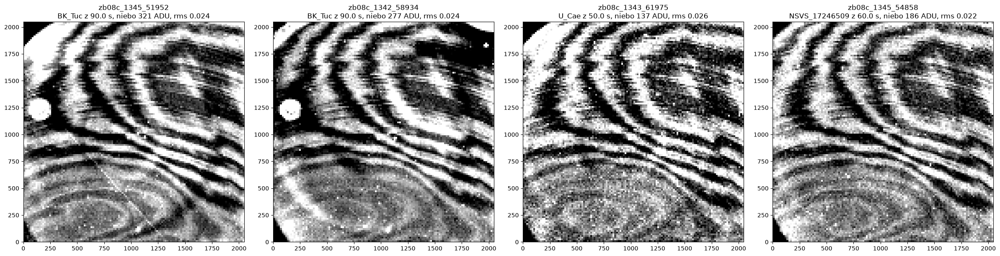

korelacja map prążków:
zb08c_1345_51952 1.00 0.66 0.78 0.72
zb08c_1342_58934 0.66 1.00 0.59 0.66
zb08c_1343_61975 0.78 0.59 1.00 0.77
zb08c_1345_54858 0.72 0.66 0.77 1.00


In [4]:
Z_FRAMES = ["zb08c_1345_51952", "zb08c_1342_58934", "zb08c_1343_61975", "zb08c_1345_54858"]

maps = []
fig, axes = plt.subplots(1, len(Z_FRAMES), figsize=(6 * len(Z_FRAMES), 6))
for ax, frame in zip(axes, Z_FRAMES):
    d = f"{SCIENCE}/{frame.split('_')[1]}/{frame}"
    h = fits.getheader(f"{d}/{frame}_zdf.fits")
    m = blocks(fits.getdata(f"{d}/{frame}_zdf.fits").astype(np.float64))
    m = m / np.median(m)
    fringes = np.clip(m - gaussian_filter(m, 12), -0.08, 0.08)   # obcinamy gwiazdy, żeby nie psuły korelacji
    maps.append(fringes)
    rms = 1.4826 * np.median(np.abs(fringes - np.median(fringes)))
    ax.imshow(fringes, origin="lower", cmap="gray", vmin=-0.03, vmax=0.03, extent=[0, 2048, 0, 2048])
    ax.set_title(f"{frame}\n{h['OBJECT']} z {h['EXPTIME']} s, niebo {np.median(blocks(fits.getdata(f'{d}/{frame}_zdf.fits'))):.0f} ADU, rms {rms:.3f}")
plt.tight_layout()
plt.show()

print("korelacja map prążków:")
for i, frame in enumerate(Z_FRAMES):
    print(frame, " ".join(f"{np.corrcoef(maps[i].ravel(), maps[j].ravel())[0, 1]:.2f}" for j in range(len(Z_FRAMES))))


## 4. Transformata Fouriera: flat i pole gwiazd z obwarzankiem

Dla porównania to samo w r, gdzie obwarzanka nie ma. Pole gwiazd: surowa klatka minus master zero (przed flatem, więc z
pełnym obwarzankiem), BK Tuc, noc 1345.

- Obwarzanek ma średnicę ~1800 px, prawie całą klatkę. W widmie siedzi więc przy samym środku: pierścienie co ~1/1800
  cykla/px, a jeden piksel widma to 1/2048. Jego koncentrycznych pierścieni (jak w `fft_basics`) tu prawie nie da się
  rozdzielić - stąd kolumna z dużym przybliżeniem.
- Brzegi klatki (zwłaszcza ciemne, winietowane rogi flatu) dają w widmie silny krzyż i smugi. `WINDOW = True` mnoży obraz
  przez okno Hanna, które wygasza go do zera przy brzegach, i większość tych smug znika (kosztem rozmycia widma o ~2 piksele).

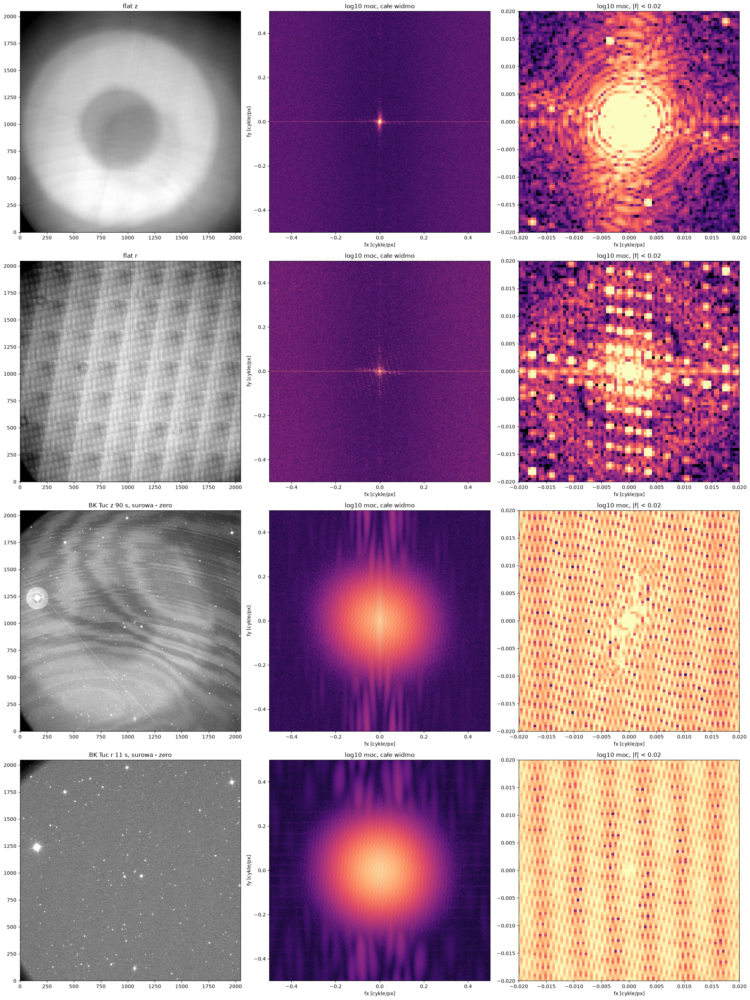

In [5]:
WINDOW = True     # okno Hanna przeciw krzyżowi od brzegów klatki
ZOOM = 0.02       # przybliżenie w trzeciej kolumnie [cykle/px] (okresy > 50 px)

CASES = [
    ("flat z", f"{FLATS}/z/zb08c_1345_46571/zb08c_1345_46571_master_f_z.fits", None),
    ("flat r", f"{FLATS}/r/zb08c_1345_47681/zb08c_1345_47681_master_f_r.fits", None),
    ("BK Tuc z 90 s, surowa - zero", f"{SCIENCE}/1345/zb08c_1345_51952/zb08c_1345_51952.fits", "zero"),
    ("BK Tuc r 11 s, surowa - zero", f"{SCIENCE}/1345/zb08c_1345_51724/zb08c_1345_51724.fits", "zero"),
]

fig, axes = plt.subplots(len(CASES), 3, figsize=(21, 7 * len(CASES)))
for (title, path, sub), (ax_im, ax_sp, ax_zoom) in zip(CASES, axes):
    img = fits.getdata(path).astype(np.float64)
    if sub == "zero":
        img = img - fits.getdata(glob.glob(f"{os.path.dirname(path)}/*_master_z.fits")[0]).astype(np.float64)
    img = img / np.median(img)                      # w jednostkach poziomu nieba / flatu
    ny, nx = img.shape

    data = img - np.median(img)
    if WINDOW:
        data = data * np.outer(np.hanning(ny), np.hanning(nx))
    power = np.abs(np.fft.fftshift(np.fft.fft2(data)))**2 / (nx * ny)
    fx = np.fft.fftshift(np.fft.fftfreq(nx))
    fy = np.fft.fftshift(np.fft.fftfreq(ny))
    logp = np.log10(power + 1e-20)
    extent = [fx[0], fx[-1], fy[0], fy[-1]]

    lo, hi = np.percentile(img, [1, 99])
    ax_im.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax_im.set_title(title)

    lo, hi = np.percentile(logp, [5, 99.99])
    ax_sp.imshow(logp, origin="lower", cmap="magma", vmin=lo, vmax=hi, extent=extent)
    ax_sp.set_title("log10 moc, całe widmo")
    ax_sp.set_xlabel("fx [cykle/px]")
    ax_sp.set_ylabel("fy [cykle/px]")

    ax_zoom.imshow(logp, origin="lower", cmap="magma", vmin=lo, vmax=hi, extent=extent)
    ax_zoom.set_xlim(-ZOOM, ZOOM)
    ax_zoom.set_ylim(-ZOOM, ZOOM)
    ax_zoom.set_title(f"log10 moc, |f| < {ZOOM}")
    ax_zoom.set_xlabel("fx [cykle/px]")
    del img, data, power, logp
plt.tight_layout()
plt.show()


## 5. Obwarzanek na wielu klatkach (filtr z)

Mapy z `sky_maps.py` (`~/data/ghost/zb08_z_*`): 43 master flaty z nocy 1290-1345 i 56 klatek nocnych (do 3 pól na noc,
EXPTIME >= 30 s). Dla każdej mapy głębokość dziury = mediana w dziurze / mediana w pierścieniu (jak w sekcji 1), dla nieba
przed flatem (surowa - zero) i po redukcji (`_zdf`). Księżyc i Słońce liczone z czasu klatki (w nagłówkach ich nie ma).

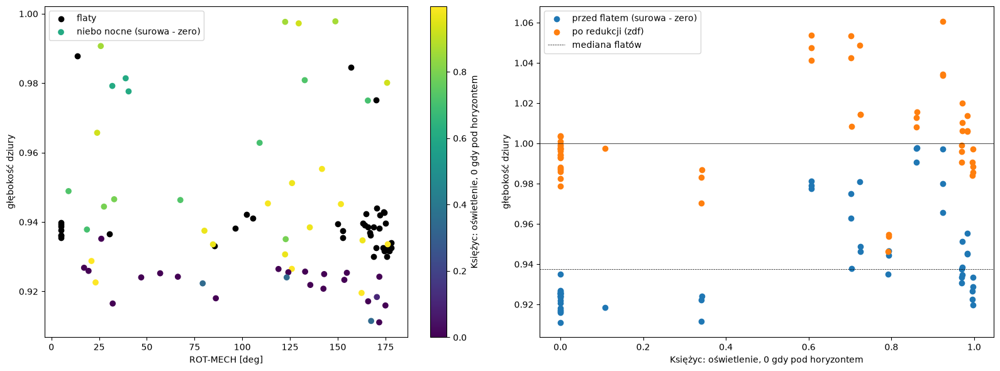

flaty: mediana 0.938, niebo bez Księżyca: 0.924, niebo z Księżycem: 0.945


In [6]:
import pandas as pd
from astropy.time import Time
from astropy.coordinates import EarthLocation, AltAz, get_body

M = np.load(os.path.expanduser("~/data/ghost/zb08_z_maps.npz"))
df = pd.read_parquet(os.path.expanduser("~/data/ghost/zb08_z_frames.parquet"))
B = int(M["block"])

yy, xx = np.mgrid[0:M["raw"].shape[1], 0:M["raw"].shape[2]] * B + B / 2
r = np.hypot(xx - XC, yy - YC)
hole, ring = r < 250, (r > 450) & (r < 600)
df["d_raw"] = [np.nanmedian(m[hole]) / np.nanmedian(m[ring]) for m in M["raw"]]
df["d_zdf"] = [np.nanmedian(m[hole]) / np.nanmedian(m[ring]) if np.isfinite(m).any() else np.nan for m in M["zdf"]]

loc = EarthLocation(lat=-24.59806, lon=-70.19638, height=2817)
t = Time(df.JD.astype(float).values, format="jd")
moon, sun = get_body("moon", t, loc), get_body("sun", t, loc)   # oba z miejsca obserwatora
df["moon_alt"] = moon.transform_to(AltAz(obstime=t, location=loc)).alt.deg
df["moon_illum"] = (1 - np.cos(sun.separation(moon).rad)) / 2      # oświetlona część tarczy

flats, sci = df[df.kind == "flat"], df[df.kind == "science"]
moon_bright = (sci.moon_alt > 0) * sci.moon_illum                   # 0 gdy Księżyc pod horyzontem

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(flats["ROT-MECH"], flats.d_raw, c="k", label="flaty")
s = axes[0].scatter(sci["ROT-MECH"], sci.d_raw, c=moon_bright, cmap="viridis", label="niebo nocne (surowa - zero)")
axes[0].set_xlabel("ROT-MECH [deg]")
axes[0].set_ylabel("głębokość dziury")
axes[0].legend()
fig.colorbar(s, ax=axes[0], label="Księżyc: oświetlenie, 0 gdy pod horyzontem")
axes[1].scatter(moon_bright, sci.d_raw, label="przed flatem (surowa - zero)")
axes[1].scatter(moon_bright, sci.d_zdf, label="po redukcji (zdf)")
axes[1].axhline(1, color="k", lw=0.5)
axes[1].axhline(np.median(flats.d_raw), color="k", ls="--", lw=0.5, label="mediana flatów")
axes[1].set_xlabel("Księżyc: oświetlenie, 0 gdy pod horyzontem")
axes[1].set_ylabel("głębokość dziury")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"flaty: mediana {flats.d_raw.median():.3f}, niebo bez Księżyca: {sci.d_raw[sci.moon_alt < 0].median():.3f}, niebo z Księżycem: {sci.d_raw[sci.moon_alt > 0].median():.3f}")


## 6. Czy obwarzanek obraca się z rotatorem?

Flaty (bez trzech nietypowych, głębokość > 0.96) w grupach według `ROT-MECH`, z każdego tylko struktura mała-średnia
(mapa / wygładzona mapa), mediana w grupie. Różnica dwóch grup: jeśli obwarzanek jest przypięty do detektora, różnica
powinna być szumem; jeśli się obraca / przesuwa, zostają pary jasny-ciemny na jego krawędziach i szprychach.

ROT ~5: 8 flatów
ROT ~100: 4 flatów
ROT ~150: 3 flatów
ROT ~170: 25 flatów


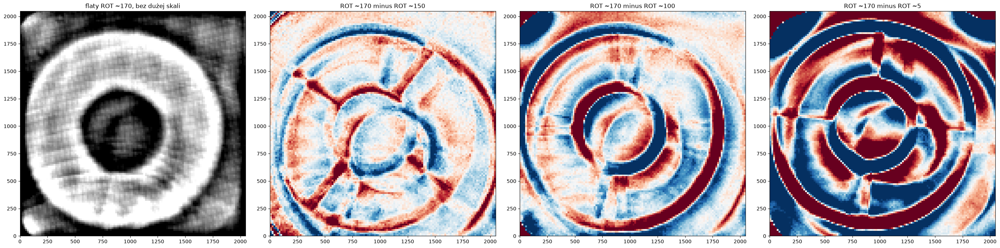

In [7]:
GROUPS = {"~5": (0, 40), "~100": (80, 120), "~150": (140, 160), "~170": (160, 180)}   # zakresy ROT-MECH [deg]

ok = flats.d_raw < 0.96
rot = flats["ROT-MECH"].astype(float)
hp = np.array([m / gaussian_filter(m, 6) for m in M["flat"][flats.index]])   # bez dużej skali (~100 px)
mean = {}
for k, (lo, hi) in GROUPS.items():
    sel = (ok & (rot >= lo) & (rot < hi)).values
    mean[k] = np.median(hp[sel], axis=0)
    print(f"ROT {k}: {sel.sum()} flatów")

fig, axes = plt.subplots(1, 4, figsize=(28, 7))
axes[0].imshow(mean["~170"], origin="lower", cmap="gray", vmin=0.99, vmax=1.01, extent=[0, 2048, 0, 2048])
axes[0].set_title("flaty ROT ~170, bez dużej skali")
for ax, k in zip(axes[1:], ["~150", "~100", "~5"]):
    ax.imshow(mean["~170"] - mean[k], origin="lower", cmap="RdBu_r", vmin=-0.004, vmax=0.004, extent=[0, 2048, 0, 2048])
    ax.set_title(f"ROT ~170 minus ROT {k}")
plt.tight_layout()
plt.show()


## 7. Rozdzielenie flatu i ghosta przez obrót

Model dla każdego flatu k (40 flatów, bez trzech nietypowych):

  flat_k(x) = F(x) + G obrócony o ROT-MECH_k wokół osi c + płaszczyzna_k

- F - flat przypięty do detektora, G - ghost w orientacji ROT = 0, płaszczyzna - gradient zmierzchu (inny na każdym flacie).
- Liczymy na zmianę: F = średnia z (flat - obrócony G - płaszczyzna); płaszczyzna = dopasowana do reszty; G = średnia z reszt
  obróconych z powrotem do ROT = 0. Kilkanaście powtórzeń.
- Część G okrągła wokół osi c nie zmienia się przy obrocie, więc nie da się jej odróżnić od F - odejmujemy ją z G (zostaje w F).
- Oś c i kierunek obrotu: wyszukane po siatce (najmniejsza reszta) - wyszło c = (1096, 968) px, kierunek +1; tu wpisane na stałe.

/tmp/ipykernel_242850/928868575.py:34: RuntimeWarning: Mean of empty slice
  F = np.nanmean(maps - P - RG, axis=0)
/tmp/ipykernel_242850/928868575.py:36: RuntimeWarning: Mean of empty slice
  G = np.nan_to_num(np.nanmean([rot(maps[k] - P[k] - F, -SIGN * t, C_AXIS) for k, t in enumerate(th)], axis=0))


reszta (rms): bez ghosta 0.0183, z obracanym ghostem 0.0070


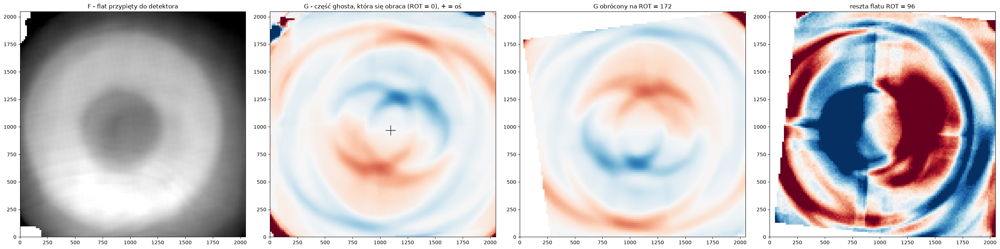

In [8]:
from scipy.ndimage import affine_transform

C_AXIS = np.array([60.0, 68.0])   # oś obrotu w blokach (y, x) -> (968, 1096) px
SIGN = 1                          # kierunek obrotu względem ROT-MECH
N_ITER = 25

ok = (flats.d_raw < 0.96).values
maps = M["flat"][flats.index][ok].astype(np.float64)
th = flats["ROT-MECH"].astype(float).values[ok]
n = maps.shape[1]
yb, xb = np.mgrid[0:n, 0:n]
X = np.c_[np.ones(n * n), xb.ravel() / n, yb.ravel() / n]         # do dopasowania płaszczyzny


def rot(img, ang, c):
    # obrót obrazka o ang stopni wokół punktu c = (y, x); poza obrazkiem NaN
    a = np.radians(ang)
    m = np.array([[np.cos(a), np.sin(a)], [-np.sin(a), np.cos(a)]])   # odwrotny obrót w kolejności (y, x)
    return affine_transform(img, m, offset=c - m @ c, order=1, cval=np.nan)


def plane(res):
    # płaszczyzna dopasowana do mapy (bez NaN)
    good = np.isfinite(res.ravel())
    coef = np.linalg.lstsq(X[good], res.ravel()[good], rcond=None)[0]
    return (X @ coef).reshape(n, n)


rr = np.hypot(yb - C_AXIS[0], xb - C_AXIS[1]).astype(int)          # promień wokół osi (do części okrągłej)
G = np.zeros((n, n))
P = np.zeros_like(maps)
for i in range(N_ITER):
    RG = np.array([rot(G, SIGN * t, C_AXIS) for t in th])
    F = np.nanmean(maps - P - RG, axis=0)
    P = np.array([plane(maps[k] - F - RG[k]) for k in range(len(maps))])
    G = np.nan_to_num(np.nanmean([rot(maps[k] - P[k] - F, -SIGN * t, C_AXIS) for k, t in enumerate(th)], axis=0))
    G = G - (np.bincount(rr.ravel(), G.ravel()) / np.bincount(rr.ravel()))[rr]   # część okrągła wokół osi -> do F

RG = np.array([rot(G, SIGN * t, C_AXIS) for t in th])
res = maps - F - RG - P
F0 = np.nanmean(maps - np.array([plane(m - np.nanmean(maps, axis=0)) for m in maps]), axis=0)   # bez ghosta: sam średni flat + płaszczyzny
print(f"reszta (rms): bez ghosta {np.nanstd(maps - F0 - np.array([plane(m - F0) for m in maps])):.4f}, z obracanym ghostem {np.sqrt(np.nanmean(res**2)):.4f}")

k96 = np.argmin(np.abs(th - 96))
fig, axes = plt.subplots(1, 4, figsize=(28, 7))
axes[0].imshow(F, origin="lower", cmap="gray", vmin=np.nanpercentile(F, 2), vmax=np.nanpercentile(F, 98), extent=[0, 2048, 0, 2048])
axes[0].set_title("F - flat przypięty do detektora")
axes[1].imshow(G, origin="lower", cmap="RdBu_r", vmin=-0.03, vmax=0.03, extent=[0, 2048, 0, 2048])
axes[1].plot(C_AXIS[1] * B + B / 2, C_AXIS[0] * B + B / 2, "k+", ms=20)
axes[1].set_title("G - część ghosta, która się obraca (ROT = 0), + = oś")
axes[2].imshow(RG[np.argmin(np.abs(th - 172))], origin="lower", cmap="RdBu_r", vmin=-0.03, vmax=0.03, extent=[0, 2048, 0, 2048])
axes[2].set_title("G obrócony na ROT = 172")
axes[3].imshow(res[k96], origin="lower", cmap="RdBu_r", vmin=-0.01, vmax=0.01, extent=[0, 2048, 0, 2048])
axes[3].set_title(f"reszta flatu ROT = {th[k96]:.0f}")
plt.tight_layout()
plt.show()


## 8. Druga dźwignia: niebo przy jasnym Księżycu jako flat bez ghosta

Przy jasnym, wysokim Księżycu obwarzanka prawie nie ma (sekcja 5). Mediana takich map nieba (surowa - zero, bez
płaszczyzny) to więc prawie „flat bez ghosta”. Odejmujemy ją od flatów i od ciemnego nieba.
Uwaga: niebo przy wysokim Księżycu to może być niebo + światło rozproszone, a nie flat bez ghosta (patrz wnioski). Tylko 4 klatki, z gwiazdami i gradientem od Księżyca - to pierwsza próba, nie gotowy flat.

               frame  OBJECT    sky  moon_alt  moon_illum  ROT-MECH  d_raw
52  zb08c_1306_51024  CN_TrA  289.5    66.726       0.861    25.864  0.991
53  zb08c_1306_52147   SA110  841.0    70.179       0.861   122.448  0.998
54  zb08c_1306_53985    TPHE  449.0    75.567       0.862   148.752  0.998
56  zb08c_1307_53416   SA110  701.5    62.081       0.924   129.535  0.997


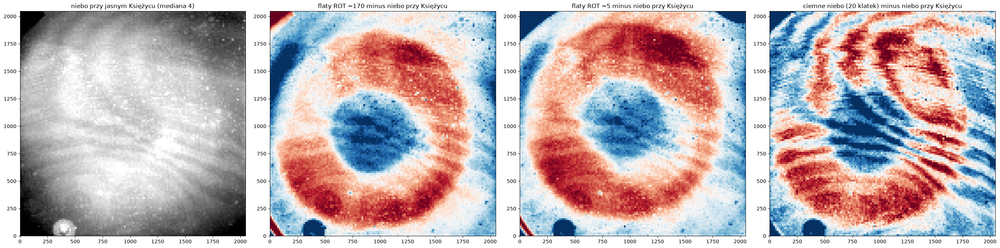

In [9]:
moonlit = sci[sci.d_raw > 0.99]
dark = sci[sci.moon_alt < 0]
print(moonlit[["frame", "OBJECT", "sky", "moon_alt", "moon_illum", "ROT-MECH", "d_raw"]].round(3).to_string())

Fm = np.median([M["raw"][i] - plane(M["raw"][i] - 1) for i in moonlit.index], axis=0)          # niebo przy Księżycu
diffs = [
    ("flaty ROT ~170 minus niebo przy Księżycu", [M["flat"][i] for i in flats.index if flats.loc[i, "ROT-MECH"] > 160 and flats.loc[i, "d_raw"] < 0.96]),
    ("flaty ROT ~5 minus niebo przy Księżycu", [M["flat"][i] for i in flats.index if flats.loc[i, "ROT-MECH"] < 10]),
    (f"ciemne niebo ({len(dark)} klatek) minus niebo przy Księżycu", [M["raw"][i] for i in dark.index]),
]

fig, axes = plt.subplots(1, 4, figsize=(28, 7))
axes[0].imshow(Fm, origin="lower", cmap="gray", vmin=np.nanpercentile(Fm, 2), vmax=np.nanpercentile(Fm, 98), extent=[0, 2048, 0, 2048])
axes[0].set_title(f"niebo przy jasnym Księżycu (mediana {len(moonlit)})")
for ax, (title, group) in zip(axes[1:], diffs):
    g = np.median([m - plane(m - 1) for m in group], axis=0) - Fm
    ax.imshow(g, origin="lower", cmap="RdBu_r", vmin=-0.06, vmax=0.06, extent=[0, 2048, 0, 2048])
    ax.set_title(title)
plt.tight_layout()
plt.show()


## 9. Czy ghost jest addytywny? Te same gwiazdy w różnych miejscach detektora

Dane z `samestar_phot.py` (`~/data/ghost/zb08_<filtr>_samestar.parquet`): fotometria aperturowa OFP (`_ap.txt`, na `_zdf`)
pól obserwowanych w danym filtrze w >= 5 nocy (noce 1290-1345). Między nocami te same gwiazdy lądują 100-250 px dalej
lub bliżej środka obwarzanka.

- Reszta gwiazdy na klatce = jej magnitudo - punkt zerowy klatki - średnie magnitudo tej gwiazdy. Własny kolor i jasność
  gwiazdy się skracają.
- P = 2.5 log10(flat_z / flat_r) w miejscu gwiazdy = to, co flat z robi inaczej niż flat r (głównie obwarzanek).
  Pc = P - średnie P tej gwiazdy.
- Nachylenie k (reszta względem Pc): **k = 0** - różnica flatów jest prawdziwa dla gwiazd (multiplikatywna, flat poprawia
  dobrze); **k = 1** - nic z niej nie jest prawdziwe (addytywna, flat psuje gwiazdy). Błąd k: bootstrap po polach.
- Test kontrolny: to samo w r, gdzie obwarzanka nie ma - powinno wyjść k = 0.

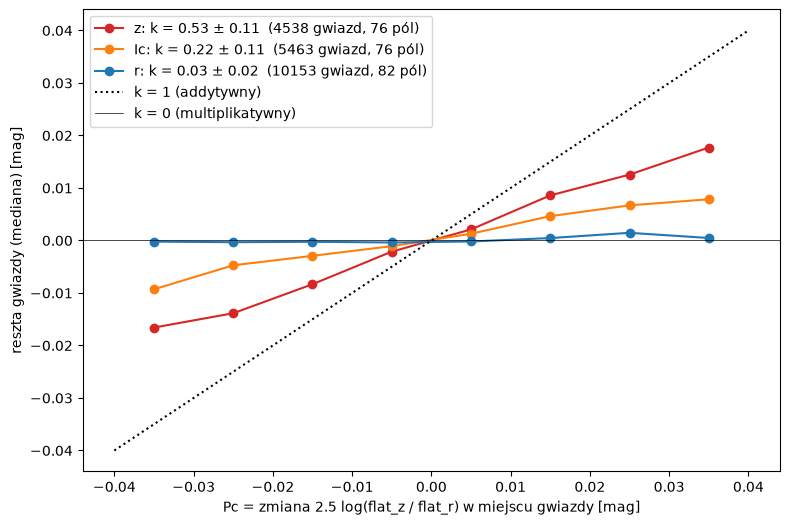

In [10]:
N_BOOT = 200
bins = np.linspace(-0.04, 0.04, 9)

fig, ax = plt.subplots(figsize=(9, 6))
for flt, color in [("z", "C3"), ("Ic", "C1"), ("r", "C0")]:
    c = pd.read_parquet(os.path.expanduser(f"~/data/ghost/zb08_{flt}_samestar.parquet"))
    use = np.abs(c.Pc) < 0.05
    k = np.polyfit(c.Pc[use], c.res[use], 1)[0]
    rng = np.random.default_rng(1)
    objs = c.obj.unique()
    ks = []
    for _ in range(N_BOOT):                      # bootstrap po polach
        s = c[c.obj.isin(rng.choice(objs, len(objs)))]
        u2 = np.abs(s.Pc) < 0.05
        ks.append(np.polyfit(s.Pc[u2], s.res[u2], 1)[0])
    m = c.groupby(pd.cut(c.Pc, bins), observed=True).res.median()
    ax.plot([iv.mid for iv in m.index], m.values, "o-", color=color, label=f"{flt}: k = {k:.2f} ± {np.std(ks):.2f}  ({c.key.nunique()} gwiazd, {c.obj.nunique()} pól)")
ax.plot(bins, bins, "k:", label="k = 1 (addytywny)")
ax.axhline(0, color="k", lw=0.5, label="k = 0 (multiplikatywny)")
ax.set_xlabel("Pc = zmiana 2.5 log(flat_z / flat_r) w miejscu gwiazdy [mag]")
ax.set_ylabel("reszta gwiazdy (mediana) [mag]")
ax.legend()
plt.show()


## 10. Jak ostry jest obwarzanek? Skale ghosta a skale flatu

Pytanie: czy ghosta da się wyciąć z flatu Ic przez dobór częstości (skal) - czyli czy jego skale są inne niż skale tego,
co we flacie chcemy zachować (piksel-do-piksela, pyłki, struktura detektora).

Dome flaty z nocy 1347 przy jednym kącie, ROT-MECH 79.9: Ic 600 s (`61623`, ~2260 ADU), V 100 s (`61485`, ~25000 ADU),
B 60 s (`61025`, ~8400 ADU). Każdy: surowa klatka minus master zero z tej nocy, podzielona przez medianę.
V ma ghosta prawie niewidocznego (~0.3 %), więc Ic/V pokazuje ghosta w Ic.

Najpierw każdy flat osobno, tylko średnie skale: obraz wygładzony o 2 px minus wygładzony o 40 px (zostaje to, co ma
rozmiar od kilku do kilkudziesięciu px).

Ic: rms piksel-do-piksela 0.0234, rms skal 2-40 px 0.0055


V: rms piksel-do-piksela 0.0072, rms skal 2-40 px 0.0032


B: rms piksel-do-piksela 0.0117, rms skal 2-40 px 0.0055


Ic / V: rms piksel-do-piksela 0.0239, rms skal 2-40 px 0.0053


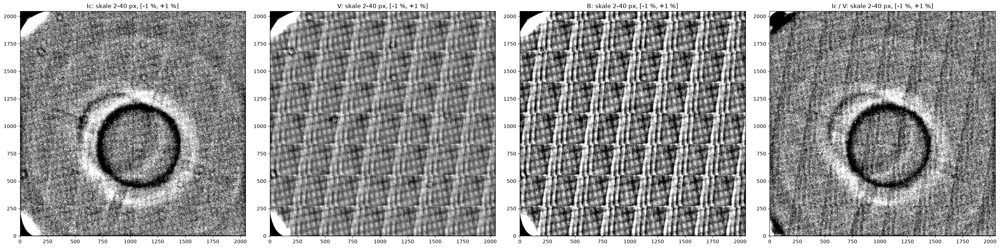

In [2]:
RAW_1347 = "/data/fits/zb08/raw/1347"
ZERO_1347 = "/data/fits/zb08/processed-ofp/zeros/zb08c_1347_50653/zb08c_1347_50653_master_z.fits"
DOME = [("Ic", "zb08c_1347_61623"), ("V", "zb08c_1347_61485"), ("B", "zb08c_1347_61025")]   # ROT-MECH 79.9
S_SMALL, S_LARGE = 2, 40   # wygładzenia do obrazków średnich skal [px]

zero = fits.getdata(ZERO_1347).astype(np.float64)
dome = {}
for flt, base in DOME:
    d = fits.getdata(f"{RAW_1347}/{base}.fits").astype(np.float64) - zero
    dome[flt] = d / np.median(d)
q_ic = dome["Ic"] / dome["V"]
q_b = dome["B"] / dome["V"]

fig, axes = plt.subplots(1, 4, figsize=(28, 7))
for ax, (title, img) in zip(axes, [("Ic", dome["Ic"]), ("V", dome["V"]), ("B", dome["B"]), ("Ic / V", q_ic)]):
    mid = gaussian_filter(img, S_SMALL) - gaussian_filter(img, S_LARGE)
    ax.imshow(mid, origin="lower", cmap="gray", vmin=-0.01, vmax=0.01)
    ax.set_title(f"{title}: skale {S_SMALL}-{S_LARGE} px, [-1 %, +1 %]")
    print(f"{title}: rms piksel-do-piksela {np.std((img - gaussian_filter(img, S_SMALL))[200:1800, 200:1800]):.4f}, rms skal {S_SMALL}-{S_LARGE} px {np.std(mid[200:1800, 200:1800]):.4f}")
plt.tight_layout()
plt.show()

Profil krawędzi dziury w Ic/V: cztery proste cięcia od środka dziury (w lewo, w prawo, w dół, w górę), każde to średnia z
pasa o szerokości `2 * HALF` px, wygładzona o 5 px. Na każdym: poziom w środku dziury (mediana 50-150 px przed krawędzią),
grzbiet za krawędzią (maksimum), i promienie, na których profil przechodzi 10 / 50 / 90 % drogi od jednego do drugiego.
Środek dziury: zaczynamy od przybliżonego i poprawiamy go dwa razy na środek między krawędziami (r50) z przeciwnych stron.

środek dziury (1082, 811) px
  lewo: r50 404 px, 10-50 % 33 px, 50-90 % 93 px, grzbiet 581 px, skok 9.3 %
 prawo: r50 405 px, 10-50 % 29 px, 50-90 % 56 px, grzbiet 507 px, skok 5.5 %
   dół: r50 410 px, 10-50 % 42 px, 50-90 % 71 px, grzbiet 518 px, skok 7.0 %
  góra: r50 411 px, 10-50 % 35 px, 50-90 % 52 px, grzbiet 501 px, skok 10.4 %


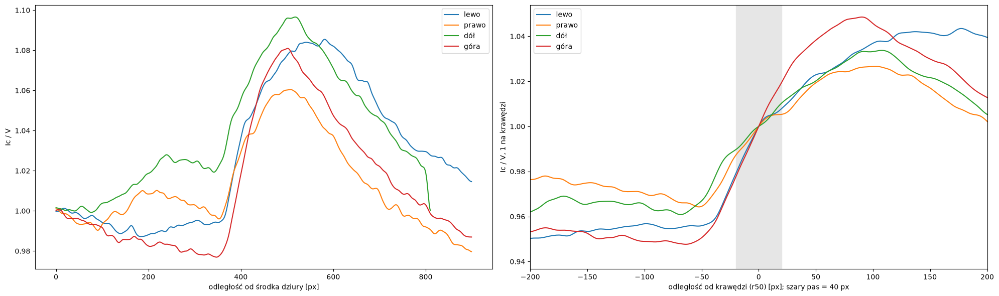

In [3]:
XC, YC = 1105, 909   # przybliżony środek dziury [px]
HALF = 25            # pół szerokości pasa cięcia [px]

for it in range(3):
    cuts = {"lewo": q_ic[YC - HALF:YC + HALF, :XC].mean(axis=0)[::-1], "prawo": q_ic[YC - HALF:YC + HALF, XC:].mean(axis=0),
            "dół": q_ic[:YC, XC - HALF:XC + HALF].mean(axis=1)[::-1], "góra": q_ic[YC:, XC - HALF:XC + HALF].mean(axis=1)}
    edge = {}
    for name, p in cuts.items():
        p = gaussian_filter(p[:900], 5)
        i = 200 + np.argmax(np.gradient(gaussian_filter(p, 10))[200:650])   # najbardziej strome miejsce
        top = i + np.argmax(p[i:i + 200])
        lo, hi = np.median(p[i - 150:i - 50]), p[top]
        f = (p - lo) / (hi - lo)
        r10, r50, r90 = [i - 100 + np.argmax(f[i - 100:] > t) for t in (0.1, 0.5, 0.9)]
        edge[name] = (p, r10, r50, r90, top, hi / lo - 1)
    if it < 2:
        XC, YC = XC + (edge["prawo"][2] - edge["lewo"][2]) // 2, YC + (edge["góra"][2] - edge["dół"][2]) // 2
print(f"środek dziury ({XC}, {YC}) px")

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for name, (p, r10, r50, r90, top, step) in edge.items():
    print(f"{name:>6}: r50 {r50} px, 10-50 % {r50 - r10} px, 50-90 % {r90 - r50} px, grzbiet {top} px, skok {100 * step:.1f} %")
    axes[0].plot(p, label=name)
    axes[1].plot(np.arange(len(p)) - r50, p / p[r50], label=name)
axes[0].set_xlabel("odległość od środka dziury [px]")
axes[0].set_ylabel("Ic / V")
axes[0].legend()
axes[1].set_xlim(-200, 200)
axes[1].axvspan(-20, 20, color="0.9")
axes[1].set_xlabel("odległość od krawędzi (r50) [px]; szary pas = 40 px")
axes[1].set_ylabel("Ic / V, 1 na krawędzi")
axes[1].legend()
plt.tight_layout()
plt.show()

Widmo mocy uśrednione po okręgach (jak w sekcji 4, z oknem Hanna) dla Ic/V i, dla porównania, B/V (bez ghosta, ale z
własnymi strukturami B i V). Od obu odjęty poziom szumu (mediana mocy przy najwyższych częstościach). Tam, gdzie Ic/V
leży wyraźnie nad B/V, w Ic/V jest coś ponad zwykłą strukturę flatów - ghost.

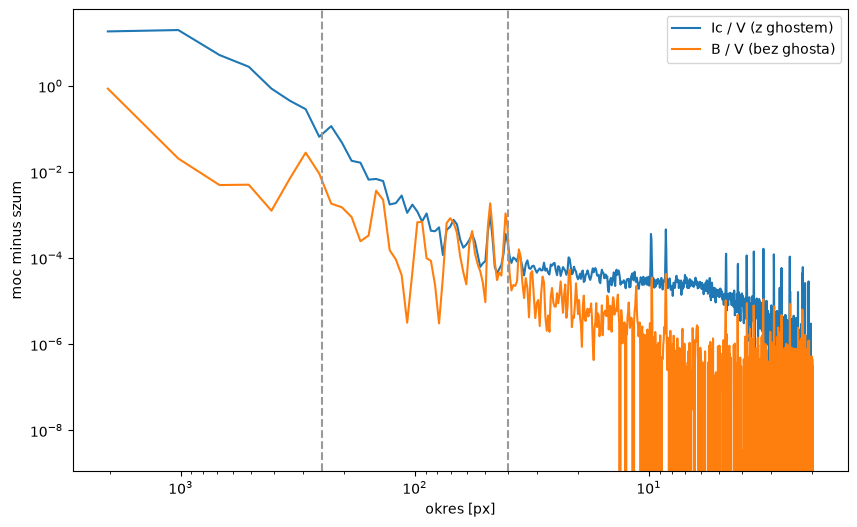

okres  1024 px: Ic/V  1.98e+01, B/V  2.05e-02
okres   512 px: Ic/V  2.79e+00, B/V  5.07e-03
okres   256 px: Ic/V  6.58e-02, B/V  9.18e-03
okres   170 px: Ic/V  1.65e-02, B/V  2.46e-04
okres   128 px: Ic/V  1.76e-03, B/V  1.52e-04
okres    85 px: Ic/V  4.31e-04, B/V  8.63e-05
okres    64 px: Ic/V  2.69e-04, B/V  1.10e-04
okres    43 px: Ic/V  5.54e-05, B/V  4.63e-05
okres    32 px: Ic/V  5.64e-05, B/V  4.38e-05
okres    21 px: Ic/V  4.49e-05, B/V  4.38e-06


In [4]:
def radial_power(img):
    # widmo mocy z oknem Hanna, uśrednione w pierścieniach |f| co 1/2048 cykla/px
    n = img.shape[0]
    data = (img - np.median(img)) * np.outer(np.hanning(n), np.hanning(n))
    power = np.abs(np.fft.fftshift(np.fft.fft2(data)))**2 / n**2
    fy, fx = np.mgrid[-n // 2:n // 2, -n // 2:n // 2]
    k = np.hypot(fx, fy).astype(int)
    return (np.bincount(k.ravel(), power.ravel()) / np.bincount(k.ravel()))[:n // 2]


p_ic, p_b = radial_power(q_ic), radial_power(q_b)
p_ic, p_b = p_ic - np.median(p_ic[700:]), p_b - np.median(p_b[700:])   # bez szumu
period = 2048 / np.arange(1, 1024)

fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(period, p_ic[1:], label="Ic / V (z ghostem)")
ax.loglog(period, p_b[1:], label="B / V (bez ghosta)")
for per in (40, 250):
    ax.axvline(per, color="0.6", ls="--")
ax.invert_xaxis()
ax.set_xlabel("okres [px]")
ax.set_ylabel("moc minus szum")
ax.legend()
plt.show()
for per in (1024, 512, 256, 170, 128, 85, 64, 43, 32, 21):
    k = 2048 // per
    print(f"okres {per:5d} px: Ic/V {p_ic[k]:9.2e}, B/V {p_b[k]:9.2e}")

### Co wyszło (2026-11-03)

- **Krawędź dziury to okrąg**: po poprawieniu środka, (1082, 811) px, r50 = 404-411 px we wszystkich czterech kierunkach.
  Środek wyznaczony progiem w sekcjach wcześniej ((1100, 910) itp.) był przesunięty przez wewnętrzny sierp.
- **Krawędź jest ostra**: od dna do połowy skoku 30-40 px, cały wzrost do grzbietu ~100 px, grzbiet ~100 px za krawędzią,
  potem powolny spadek. Skok 5-10 % zależnie od strony, dno dziury 0.95-0.975 względem krawędzi.
- **Widmo**: Ic/V jest > 10x nad B/V dla okresów > ~130 px, 3-5x przy 60-85 px, przy ~40 px już porównywalne. Poniżej 40 px
  Ic/V ma płaskie plateau ponad B/V - to raczej szum słabego flatu Ic (2260 ADU, rms piksel-do-piksela 2.3 %, prawie
  sam Poisson) niż ghost; nie rozstrzygnięte.
- **Flaty V i B mają własną strukturę**, której w Ic prawie nie ma: siatkę ukośnych pasów co ~250 px i poziomych pasów
  (najsilniejsza w B, rms skal 2-40 px 0.55 %, w V 0.32 %), oraz pyłki - małe obwarzanki ~40-60 px. Flat V czy B nie
  nadaje się więc wprost do Ic, a Ic/V przenosi odwróconą siatkę V.
- **Wniosek dla usuwania ghosta**: prosty podział częstości nie wystarczy - stroma krawędź (~35 px) siedzi na tych samych
  skalach co pyłki, a ghost ma moc aż do okresów ~40 px. Ghosta trzeba raczej opisać modelem z kilkoma parametrami (środek,
  promień ~407 px, profil krawędzi, amplituda, wnętrze z sierpem i pająkiem obracającymi się z rotatorem) dopasowanym do
  Ic/V lub Ic/B; to, co nie jest modelem (pyłki, siatka V, piksele), wtedy w Ic zostaje.

## 11. Które skale są wspólne dla filtrów? Korelacja flatów w pasmach częstości

Master flaty zmierzchowe z nocy 1345 (wieczór, ROT-MECH ~172): u, g, V, r, Ic, i, z; B z nocy 1346 (wieczór, ~173), bo w
1345 go nie ma. Do tego z, i, r z rana tej samej nocy (ROT-MECH 5) - ten sam filtr przy innym kącie i innym niebie.

Dla każdej pary flatów i każdego pasma okresów (oktawy: 1024-512 px, 512-256 px, ...):

  r = Re Σ F1 · F2* / sqrt(Σ |F1|² · Σ |F2|²),   suma po pikselach widma w tym pasmie

F1, F2 to transformaty obu flatów (z fazą, okno Hanna). To jest zwykły współczynnik korelacji obu flatów przefiltrowanych
do tego pasma: 1 - ta sama struktura w tym samym miejscu, 0 - struktury niezależne lub w innych miejscach. Faza tu
jest ważna: samo widmo mocy nie wie, gdzie co leży, więc nie odróżni pyłków w tym samym miejscu od pyłków gdzie indziej.

Ile daje sam szum, pokazują pary tego samego filtra (wieczór - rano): na najmniejszych skalach ~0.55 - więcej się
nie da.

okres [px]      1024-512    512-256    256-128    128-64      64-32      32-16      16-8        8-4        4-2   
      Ic - z         0.96       0.76       0.68       0.67       0.86       0.65       0.47       0.39       0.55
      Ic - i         0.77       0.59       0.66       0.88       0.95       0.72       0.51       0.39       0.55
       i - z         0.83       0.77       0.62       0.62       0.82       0.64       0.47       0.37       0.54
      Ic - V        -0.21       0.43       0.44       0.76       0.83       0.67       0.52       0.40       0.54
       z - V        -0.40       0.13       0.17       0.54       0.72       0.61       0.47       0.39       0.53
       r - V         0.72       0.96       0.99       0.99       0.97       0.85       0.66       0.41       0.53
       V - B         0.95       0.97       0.97       0.95       0.90       0.87       0.76       0.47       0.54
       g - B         0.89       0.99       1.00       1.00       1.00       0.97       0

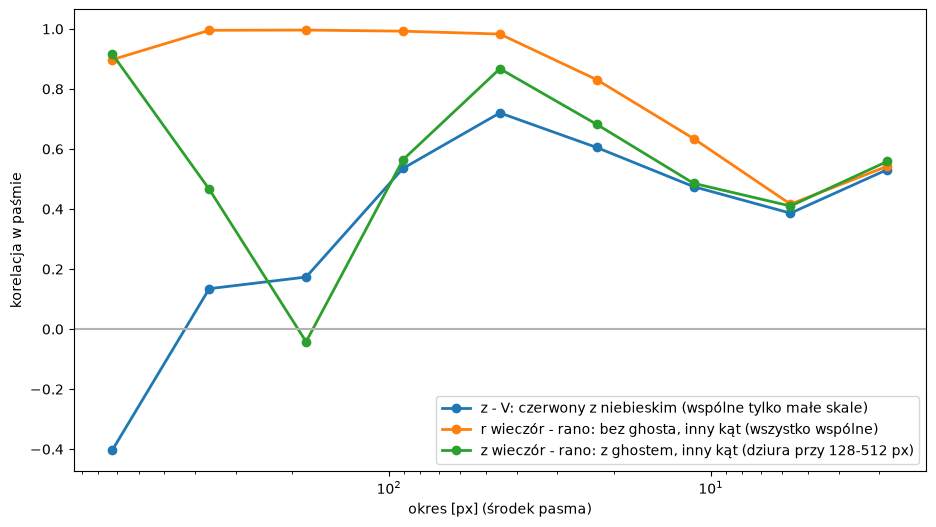

In [4]:
FLATS_1345 = {"u": "zb08c_1345_46185", "B": "zb08c_1346_47042", "g": "zb08c_1345_47172", "V": "zb08c_1345_47011",
              "r": "zb08c_1345_47681", "Ic": "zb08c_1345_46857", "i": "zb08c_1345_47368", "z": "zb08c_1345_46571",
              "z rano": "zb08c_1345_90205", "i rano": "zb08c_1345_89547", "r rano": "zb08c_1345_89280"}
EDGES = [1024, 512, 256, 128, 64, 32, 16, 8, 4, 2]   # granice pasm [okres w px]
PAIRS = [("Ic", "z"), ("Ic", "i"), ("i", "z"), ("Ic", "V"), ("z", "V"), ("r", "V"), ("V", "B"), ("g", "B"), ("u", "B"), ("u", "z"),
         ("r", "r rano"), ("i", "i rano"), ("z", "z rano")]
PLOT = {("z", "V"): "z - V: czerwony z niebieskim (wspólne tylko małe skale)",
        ("r", "r rano"): "r wieczór - rano: bez ghosta, inny kąt (wszystko wspólne)",
        ("z", "z rano"): "z wieczór - rano: z ghostem, inny kąt (dziura przy 128-512 px)"}   # pary na wykresie

n = 2048
hann = np.outer(np.hanning(n), np.hanning(n))
F = {}
for name, base in FLATS_1345.items():
    flt = name.split()[0]
    d = fits.getdata(f"{FLATS}/{flt}/{base}/{base}_master_f_{flt}.fits").astype(np.float64)
    d = np.nan_to_num(d / np.nanmedian(d), nan=1.0)
    F[name] = np.fft.fft2((d - d.mean()) * hann)

fy, fx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n), indexing="ij")
fr = np.hypot(fx, fy)                                                   # |f| [cykle/px]
bands = [(fr >= 1 / p1) & (fr < 1 / p2) for p1, p2 in zip(EDGES[:-1], EDGES[1:])]

corr = {}
for a, b in PAIRS:
    corr[(a, b)] = [np.real(np.sum(F[a][m] * np.conj(F[b][m]))) / np.sqrt(np.sum(np.abs(F[a][m])**2) * np.sum(np.abs(F[b][m])**2)) for m in bands]

print("okres [px]     " + " ".join(f"{p1:>5}-{p2:<4}" for p1, p2 in zip(EDGES[:-1], EDGES[1:])))
for (a, b), v in corr.items():
    print(f"{a + ' - ' + b:>12}   " + " ".join(f"{x:10.2f}" for x in v))

mid = [np.sqrt(p1 * p2) for p1, p2 in zip(EDGES[:-1], EDGES[1:])]   # środek pasma [px]
fig, ax = plt.subplots(figsize=(11, 6))
for pair, label in PLOT.items():
    ax.semilogx(mid, corr[pair], marker="o", lw=2, label=label)
ax.invert_xaxis()
ax.axhline(0, color="0.7")
ax.set_xlabel("okres [px] (środek pasma)")
ax.set_ylabel("korelacja w paśmie")
ax.legend()
plt.show()
del F

### Co wyszło (2026-11-03)

- **Poniżej ~32 px wszystkie filtry mają to samo**: z - V, Ic - V są tak samo wysokie jak ten sam filtr wieczór - rano
  (na pikselach V - z 0.53, z - z 0.56, czyli na granicy szumu). PRNU i drobne defekty w V są takie same jak w Ic i z.
- **32-64 px (pyłki) - w dużej części wspólne**: Ic - V 0.83, z - V 0.72, u - B 0.94. Większość pyłków leży na powierzchni
  wspólnej dla wszystkich filtrów (okienko, detektor), nie na filtrach; własnych pyłków filtra jest mniej (korelacje
  między filtrami trochę niższe niż ten sam filtr wieczór - rano).
- **~128-512 px to ghost**: r wieczór - rano (inny kąt rotatora) 0.99-1.00, a z wieczór - rano -0.04 (128-256 px) i 0.47
  (256-512 px) - w z ta część zmienia się z kątem, w r jej nie ma. Czerwony z niebieskim korelują tu słabo (z - V 0.13-0.17).
- **Niebieskie filtry (u, B, g, V, r) mają tę samą strukturę na 128-512 px** (0.95-1.00): to siatka co ~250 px, przypięta do
  detektora i wspólna dla błękitu, w czerwieni jej nie ma. Duże skale V nie nadają się do Ic / z.
- Najniższe pasmo (1024-512 px): winietowanie wspólne, ale w czerwonych dochodzi duży dysk ghosta, stąd ujemne wartości
  Ic - V, z - V.
- **Wniosek - podział na trzy pasma**: poniżej ~64 px z V (PRNU i większość pyłków), ~64-500 px ghost do wymodelowania,
  powyżej ~500 px z własnego flatu filtra (winietowanie, człon kolorowy). Granice przybliżone; to flaty zmierzchowe, w
  których ghost jest słabszy niż w dome.

## 12. Model ghosta po okręgu

Ic / V z sekcji 10 (dome flaty, ROT-MECH 79.9) we współrzędnych biegunowych wokół środka dziury (XC, YC) = (1082, 811) px
z sekcji 10. Ghost ma ostrą krawędź wzdłuż promienia (~35 px), ale wzdłuż okręgu zmienia się powoli. Pyłki, siatka V i
szum nie mają takiej symetrii względem tego środka.

Dzielimy obraz na pierścienie o szerokości `R_STEP` px. W każdym pierścieniu dopasowujemy do pikseli szereg Fouriera w
kącie φ (najmniejsze kwadraty):

  model(r, φ) = c0(r) + Σ_(m=1..M) [a_m(r) cos(mφ) + b_m(r) sin(mφ)]

- m = 0 - część okrągła (średnia po okręgu),
- m = 1 - przesunięcie (decentracja), m = 2 - spłaszczenie (elipsa), wyższe m - drobniejsze zmiany po okręgu (sierp, pająk).

Pyłek ~50 px na okręgu r = 400 px (obwód ~2500 px) to ~2 % pierścienia; dodatkowo po pierwszym dopasowaniu odrzucamy
piksele dalej niż `CLIP` sigm (z MAD) i dopasowujemy jeszcze raz, więc pyłki prawie nie wchodzą do modelu i zostają w
reszcie. Współczynniki między środkami pierścieni interpolowane liniowo w r (żeby nie było schodków co `R_STEP`).
Pierścienie, w których jest mniej niż `MIN_COVER` pełnego okręgu (dalej niż brzeg klatki), pomijamy - tam model = NaN.

Uwaga: do modelu wchodzi wszystko, co jest okrągłe wokół tego środka - także okrągła część różnicy kolorów Ic / V. Tu
patrzymy tylko, czy model zabiera ghosta, a zostawia pyłki.

In [4]:
R_STEP = 4            # szerokość pierścienia [px]
R_MAX = 1000          # do jakiego promienia modelować [px]
M_LIST = [0, 1, 2, 4, 8]   # ile harmonicznych kąta - do porównania
M_SHOW = 4            # który model pokazać na obrazkach
CLIP = 4              # odrzucanie pikseli dalej niż CLIP sigm od pierwszego dopasowania
MIN_COVER = 0.6       # minimalna część okręgu w klatce

yy, xx = np.mgrid[0:2048, 0:2048]
rr = np.hypot(xx - XC, yy - YC)
phi = np.arctan2(yy - YC, xx - XC)
ring = (rr // R_STEP).astype(int)
r_mid = (np.arange(R_MAX // R_STEP) + 0.5) * R_STEP
ring_pix = [np.flatnonzero(ring == k) for k in range(len(r_mid))]   # piksele każdego pierścienia


def design(ph, m_max):
    # kolumny 1, cos(phi), sin(phi), ..., cos(m_max phi), sin(m_max phi)
    return np.column_stack([np.ones_like(ph)] + [f(m * ph) for m in range(1, m_max + 1) for f in (np.cos, np.sin)])


models, coefs = {}, {}
for M in M_LIST:
    coef = np.full((len(r_mid), 2 * M + 1), np.nan)
    for k, idx in enumerate(ring_pix):
        if len(idx) < MIN_COVER * 2 * np.pi * r_mid[k] * R_STEP or len(idx) < 10 * (2 * M + 1):
            continue
        A, y = design(phi.flat[idx], M), q_ic.flat[idx]
        c = np.linalg.lstsq(A, y, rcond=None)[0]
        res = y - A @ c
        keep = np.abs(res) < CLIP * 1.4826 * np.median(np.abs(res))
        coef[k] = np.linalg.lstsq(A[keep], y[keep], rcond=None)[0]
    good = np.isfinite(coef[:, 0])
    inside = (rr >= r_mid[good][0]) & (rr <= r_mid[good][-1])
    model = np.full(q_ic.shape, np.nan)
    cols = design(phi[inside], M)
    model[inside] = sum(np.interp(rr[inside], r_mid[good], coef[good, j]) * cols[:, j] for j in range(2 * M + 1))
    models[M], coefs[M] = model, coef
    del cols

# jak dobrze: rms reszty (q / model - 1) na dużych skalach (wygładzone o 20 px) i na średnich (2-40 px), w r < R_MAX
# poza obszarem modelu (środek, brzegi) reszta = 1, żeby wygładzanie nie roznosiło NaN
inside = np.isfinite(models[max(M_LIST)])
away = inside & ((rr < 300) | (rr > 550))            # z dala od krawędzi dziury (tam skale 2-40 px to sam ghost)
mid_q = gaussian_filter(q_ic, 2) - gaussian_filter(q_ic, 40)
print(f"Ic / V bez modelu: rms dużych skal {np.std(gaussian_filter(q_ic, 20)[inside]):.4f}, rms skal 2-40 px {np.std(mid_q[inside]):.4f}")
for M in M_LIST:
    res = np.where(np.isfinite(models[M]), q_ic / models[M], 1.0)
    mid_r = gaussian_filter(res, 2) - gaussian_filter(res, 40)
    print(f"M = {M}: rms dużych skal {np.std(gaussian_filter(res, 20)[inside]):.4f}, rms skal 2-40 px {np.std(mid_r[inside]):.4f}, "
          f"korelacja skal 2-40 px z Ic / V: wszędzie {np.corrcoef(mid_r[inside], mid_q[inside])[0, 1]:.3f}, z dala od krawędzi {np.corrcoef(mid_r[away], mid_q[away])[0, 1]:.3f}")

Ic / V bez modelu: rms dużych skal 0.0336, rms skal 2-40 px 0.0054


M = 0: rms dużych skal 0.0164, rms skal 2-40 px 0.0047, korelacja skal 2-40 px z Ic / V: wszędzie 0.836, z dala od krawędzi 0.940


M = 1: rms dużych skal 0.0052, rms skal 2-40 px 0.0044, korelacja skal 2-40 px z Ic / V: wszędzie 0.853, z dala od krawędzi 0.978


M = 2: rms dużych skal 0.0034, rms skal 2-40 px 0.0044, korelacja skal 2-40 px z Ic / V: wszędzie 0.848, z dala od krawędzi 0.975


M = 4: rms dużych skal 0.0021, rms skal 2-40 px 0.0043, korelacja skal 2-40 px z Ic / V: wszędzie 0.835, z dala od krawędzi 0.963


M = 8: rms dużych skal 0.0015, rms skal 2-40 px 0.0042, korelacja skal 2-40 px z Ic / V: wszędzie 0.817, z dala od krawędzi 0.945


Obrazki: Ic / V, model z `M_SHOW` harmonicznymi, reszta Ic / V / model (wygładzona o 2 px), i średnie skale (2-40 px)
przed i po - pyłki powinny zostać takie same. Pod spodem profil części okrągłej c0(r) i siła harmonicznych
sqrt(a_m² + b_m²) w funkcji promienia.

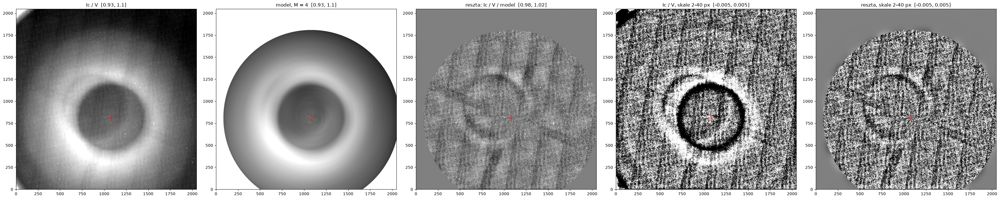

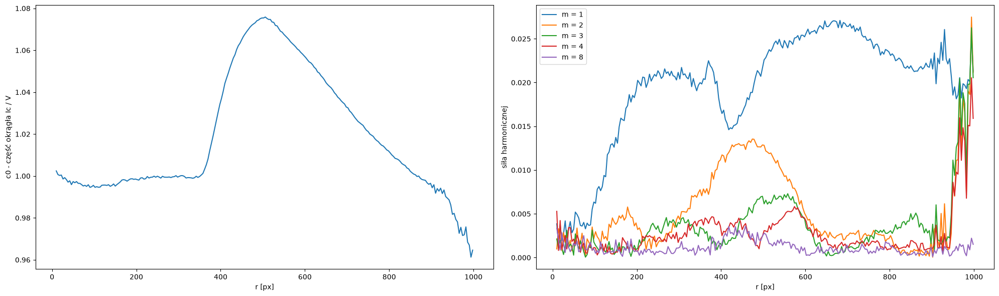

In [5]:
res = np.where(np.isfinite(models[M_SHOW]), q_ic / models[M_SHOW], 1.0)
mid_r = gaussian_filter(res, 2) - gaussian_filter(res, 40)
panels = [("Ic / V", gaussian_filter(q_ic, 2), 0.93, 1.10, "gray"),
          (f"model, M = {M_SHOW}", models[M_SHOW], 0.93, 1.10, "gray"),
          ("reszta: Ic / V / model", gaussian_filter(res, 2), 0.98, 1.02, "gray"),
          ("Ic / V, skale 2-40 px", mid_q, -0.005, 0.005, "gray"),
          ("reszta, skale 2-40 px", mid_r, -0.005, 0.005, "gray")]
fig, axes = plt.subplots(1, 5, figsize=(35, 7))
for ax, (title, img, lo, hi, cmap) in zip(axes, panels):
    ax.imshow(img, origin="lower", cmap=cmap, vmin=lo, vmax=hi)
    ax.plot(XC, YC, "r+", ms=15)
    ax.set_title(f"{title}  [{lo}, {hi}]")
plt.tight_layout()
plt.show()

M = max(M_LIST)
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
axes[0].plot(r_mid, coefs[M][:, 0])
axes[0].set_xlabel("r [px]")
axes[0].set_ylabel("c0 - część okrągła Ic / V")
for m in (1, 2, 3, 4, 8):
    axes[1].plot(r_mid, np.hypot(coefs[M][:, 2 * m - 1], coefs[M][:, 2 * m]), label=f"m = {m}")
axes[1].set_xlabel("r [px]")
axes[1].set_ylabel("siła harmonicznej")
axes[1].legend()
plt.tight_layout()
plt.show()

### Co wyszło (2026-11-03)

- **Model po okręgu zabiera prawie całego ghosta**: rms dużych skal (wygładzone o 20 px) Ic / V 3.4 % -> M = 0: 1.6 %,
  M = 1: 0.52 %, M = 2: 0.34 %, M = 4: 0.21 %, M = 8: 0.15 %.
- **Małe skale zostają**: z dala od krawędzi dziury korelacja skal 2-40 px reszty z Ic / V 0.98 (M = 1), 0.975 (M = 2),
  0.96 (M = 4); przy M = 8 spada do 0.945 - model zaczyna zjadać pyłki. Rozsądnie M = 2-4.
- **Co zostaje w reszcie (M = 4)**:
  - cienki łuk na krawędzi dziury (~0.5 %, góra i dół): krawędź nie jest dokładnie okręgiem wokół tego środka, a ostrej,
    przesuniętej krawędzi kilka harmonicznych nie odtworzy;
  - proste ciemne pasy przez dziurę (~0.5-1 %): pająk lustra wtórnego w obrazie źrenicy. Wąskie w kącie, więc wymagałyby
    wysokich m; obracają się z rotatorem - kandydat na osobny składnik o znanej geometrii (proste linie);
  - pionowawe pasy siatki - z V (mianownik), nie z Ic.
- **Profil c0(r)**: płasko do r ~360 px, wzrost 360-500 px do 1.075, potem liniowy spadek do 0.96 przy r = 1000 px, bez
  widocznego końca ghosta. Zewnętrzne zbocze to ghost + okrągła część różnicy kolorów Ic / V - tu nie do rozdzielenia.
- **Harmoniczne**: m = 1 ~2-2.5 % od r = 200 px do brzegu (decentracja + gradient Ic / V na całej klatce), m = 2 do 1.3 % przy
  r ~470 px (krawędź), m = 3, 4 ~0.5 % przy r = 500-580 px (sierp).
- Dalej: pająk jako osobny składnik; środek dopasowany do samej krawędzi; ten sam model na wszystkich kątach (1346 i 1347)
  i sprawdzian zgodności poprawionych flatów Ic; zastosowanie do flatu Ic, nie tylko Ic / V.

## 13. Oddzielenie ghosta od różnicy kolorów Ic / V

Model z sekcji 12 zawiera wszystko, co jest okrągłe wokół środka dziury - także wolną różnicę kolorów Ic / V (QE,
niejednorodność filtrów), która jest prawdziwą częścią flatu Ic i musi w nim zostać.

Założenie: ghosta nie ma w środku dziury (r < `R_HOLE`) i daleko od niej (r > `R_END`). Tam Ic / V to sama różnica
kolorów. Dopasowujemy do tych miejsc gładką powierzchnię S(x, y) - wielomian stopnia `ORDER` w x i y (na mapie median w
blokach 16 px, bez pasa `EDGE` px przy brzegach klatki) - i przeciągamy ją pod pierścień ghosta. Ghost = Ic / V / S.

Jednorodny "cokół" ghosta (to samo światło dodane wszędzie) nie ma znaczenia: flat i tak normalizujemy.

Gdzie ghost się kończy, nie wiemy - stąd kilka wartości `R_END` i porównanie profili.

R_END = 700: S od 0.908 do 1.026, rms reszty dopasowania 0.0161, punktów 9814
R_END = 800: S od 0.913 do 1.015, rms reszty dopasowania 0.0131, punktów 8047


R_END = 900: S od 0.913 do 1.008, rms reszty dopasowania 0.0106, punktów 6281
R_END = 1000: S od 0.911 do 1.004, rms reszty dopasowania 0.0089, punktów 4666


kształt S przy R_END = 700 względem 900: rms 0.0048, max |różnica| 0.0181
kształt S przy R_END = 800 względem 900: rms 0.0017, max |różnica| 0.0062
kształt S przy R_END = 900 względem 900: rms 0.0000, max |różnica| 0.0000
kształt S przy R_END = 1000 względem 900: rms 0.0021, max |różnica| 0.0066


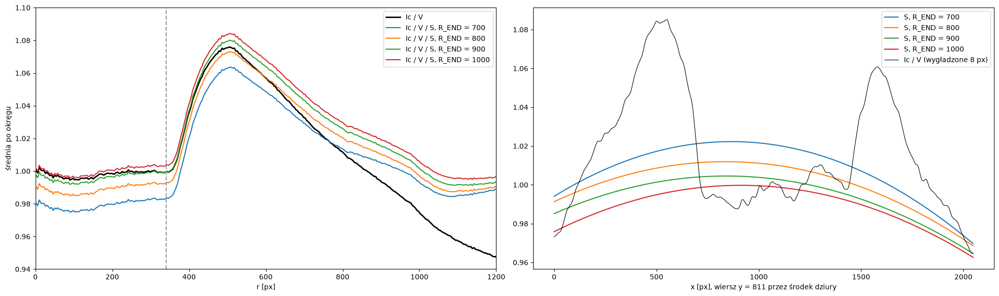

In [5]:
R_HOLE = 340                       # do tego promienia (środek dziury) ghosta nie ma [px]
R_ENDS = [700, 800, 900, 1000]     # od tego promienia ghosta nie ma - kilka wersji [px]
ORDER = 2                          # stopień wielomianu S(x, y)
EDGE = 64                          # pas przy brzegach klatki pomijany przy dopasowaniu [px]

qb = blocks(q_ic, 16)
yb, xb = np.mgrid[0:128, 0:128] * 16 + 8
rb = np.hypot(xb - XC, yb - YC)
in_frame = (xb > EDGE) & (xb < 2048 - EDGE) & (yb > EDGE) & (yb < 2048 - EDGE)


def poly_cols(x, y):
    # kolumny x^i y^j, i + j <= ORDER (x, y przeskalowane do -1..1)
    x, y = (x - 1024) / 1024, (y - 1024) / 1024
    return np.column_stack([x**i * y**j for i in range(ORDER + 1) for j in range(ORDER + 1 - i)])


S_maps, ghost_maps = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
prof_q = np.bincount(ring.ravel(), q_ic.ravel()) / np.bincount(ring.ravel())
axes[0].plot((np.arange(len(prof_q)) + 0.5) * R_STEP, prof_q, "k", lw=2, label="Ic / V")
for R_END in R_ENDS:
    use = in_frame & ((rb < R_HOLE) | (rb > R_END))
    c = np.linalg.lstsq(poly_cols(xb[use], yb[use]), qb[use], rcond=None)[0]
    S = (poly_cols(xx.ravel(), yy.ravel()) @ c).reshape(q_ic.shape)
    g = q_ic / S
    S_maps[R_END], ghost_maps[R_END] = S, g
    prof = np.bincount(ring.ravel(), g.ravel()) / np.bincount(ring.ravel())
    axes[0].plot((np.arange(len(prof)) + 0.5) * R_STEP, prof, label=f"Ic / V / S, R_END = {R_END}")
    print(f"R_END = {R_END}: S od {S[in_frame.repeat(16, 0).repeat(16, 1)].min():.3f} do {S.max():.3f}, "
          f"rms reszty dopasowania {np.std(qb[use] / (poly_cols(xb[use], yb[use]) @ c) - 1):.4f}, punktów {use.sum()}")
axes[0].axvline(R_HOLE, color="0.6", ls="--")
axes[0].set_xlim(0, 1200)
axes[0].set_ylim(0.94, 1.10)
axes[0].set_xlabel("r [px]")
axes[0].set_ylabel("średnia po okręgu")
axes[0].legend()
frame = in_frame.repeat(16, 0).repeat(16, 1)
ref = S_maps[900] / np.median(S_maps[900][frame])
for R_END in R_ENDS:
    d = S_maps[R_END] / np.median(S_maps[R_END][frame]) / ref - 1    # różnica kształtu (bez stałej) względem R_END = 900
    print(f"kształt S przy R_END = {R_END} względem 900: rms {np.std(d[frame]):.4f}, max |różnica| {np.abs(d[frame]).max():.4f}")
    axes[1].plot(xx[YC], S_maps[R_END][YC], label=f"S, R_END = {R_END}")
axes[1].plot(xx[YC], gaussian_filter(q_ic, 8)[YC], "k", lw=0.8, label="Ic / V (wygładzone 8 px)")
axes[1].set_xlabel(f"x [px], wiersz y = {YC} przez środek dziury")
axes[1].legend()
plt.tight_layout()
plt.show()

Model ghosta z jednej wersji (`R_USE`): to samo co w sekcji 12 (szereg Fouriera w kącie, `M_SHOW` harmonicznych, w
pierścieniach), ale na Ic / V / S. Poprawiony flat Ic = Ic / model ghosta (poza zasięgiem modelu bez zmian).
Sprawdzian: poprawiony Ic / V powinien być gładki (sama różnica kolorów S, siatka V, pyłki, szum) - bez pierścienia.

model ghosta: od 0.976 do 1.103


rms dużych skal (wygładzone 20 px, r < 998 px): Ic / V 0.0336, poprawiony Ic / V 0.0139, S 0.0137


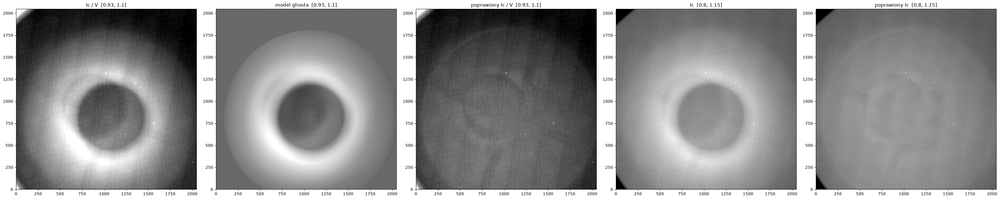

In [6]:
R_USE = 900         # która wersja R_END

g = ghost_maps[R_USE]
coef = np.full((len(r_mid), 2 * M_SHOW + 1), np.nan)
for k, idx in enumerate(ring_pix):
    if len(idx) < MIN_COVER * 2 * np.pi * r_mid[k] * R_STEP:
        continue
    A, y = design(phi.flat[idx], M_SHOW), g.flat[idx]
    c = np.linalg.lstsq(A, y, rcond=None)[0]
    keep = np.abs(y - A @ c) < CLIP * 1.4826 * np.median(np.abs(y - A @ c))
    coef[k] = np.linalg.lstsq(A[keep], y[keep], rcond=None)[0]
ok = np.isfinite(coef[:, 0])
ghost_model = np.ones(q_ic.shape)
inside = rr <= r_mid[ok][-1]
cols = design(phi[inside], M_SHOW)
ghost_model[inside] = sum(np.interp(rr[inside], r_mid[ok], coef[ok, j]) * cols[:, j] for j in range(2 * M_SHOW + 1))
del cols
ic_corr = dome["Ic"] / ghost_model
q_corr = ic_corr / dome["V"]
print(f"model ghosta: od {np.nanmin(ghost_model):.3f} do {np.nanmax(ghost_model):.3f}")
print(f"rms dużych skal (wygładzone 20 px, r < {r_mid[ok][-1]:.0f} px): Ic / V {np.std(gaussian_filter(q_ic, 20)[inside]):.4f}, "
      f"poprawiony Ic / V {np.std(gaussian_filter(q_corr, 20)[inside]):.4f}, S {np.std(S_maps[R_USE][inside]):.4f}")

panels = [("Ic / V", gaussian_filter(q_ic, 4), 0.93, 1.10), ("model ghosta", ghost_model, 0.93, 1.10),
          ("poprawiony Ic / V", gaussian_filter(q_corr, 4), 0.93, 1.10), ("Ic", gaussian_filter(dome["Ic"], 4), 0.8, 1.15),
          ("poprawiony Ic", gaussian_filter(ic_corr, 4), 0.8, 1.15)]
fig, axes = plt.subplots(1, 5, figsize=(35, 7))
for ax, (title, img, lo, hi) in zip(axes, panels):
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"{title}  [{lo}, {hi}]")
plt.tight_layout()
plt.show()

### Co wyszło (2026-11-03)

- **Różnica kolorów Ic / V (S)** to łagodna kopuła: jaśniej w środku klatki, ~2.5-3 % ciemniej przy brzegach w wierszu
  przez dziurę, 0.91-1.01 na całej klatce.
- **Wybór R_END mało zmienia kształt S**: po odjęciu stałej (która dla flatu nie gra roli) S przy R_END = 800 i 1000 różni
  się od wersji 900 o 0.2 % rms (max 0.6 %); przy 700 o 0.5 % rms (max 1.8 %) i dopasowanie gorsze (rms reszty 1.6 % zamiast
  ~1 %) - przy 700 px ghost jeszcze jest. Ghost kończy się więc gdzieś między 800 a 1000 px; w tym zakresie wynik stabilny
  na ~0.2 %.
- **Model ghosta (R_END = 900, M = 4)**: od 0.976 do 1.103, czyli pierścień do +10 %, a w dziurze lekko poniżej 1.
- **Poprawiony Ic**: obwarzanka prawie nie ma. Poprawiony Ic / V ma rms dużych skal 1.39 % - tyle co sama S (1.37 %), czyli
  zostaje w nim głównie różnica kolorów, tak jak powinno. Widać jeszcze: słaby łuk krawędzi i pająka (jak w sekcji 12).
- Założenie "w dziurze ghosta nie ma" jest nie do sprawdzenia z jednego flatu; jednorodny cokół nie szkodzi, ale gładka
  zmiana ghosta wewnątrz dziury weszłaby do S.

## 14. Test na wszystkich kątach: czy poprawione flaty się zgadzają?

Przepis z sekcji 13 (środek dziury z cięć jak w sekcji 10 -> S z miejsc bez ghosta -> model po okręgu na Ic / V / S ->
Ic / V / model) powtórzony dla każdego dome flatu Ic z nocy 1346 i 1347, każdy ze swoim V przy tym samym kącie.
1346 do `80168` ma starą (błędną) skalę `ROT-MECH`, od `82034` nową; Ic `82034` nie ma V przy swoim kącie - bierze V
`80168` (ostatni przed poprawką telemetrii, fizycznie blisko).

Sprawdzian: Ic / V przy różnych kątach różni się, bo ghost przesuwa się i obraca, a różnica kolorów (S) jest przypięta do
kamery. Po usunięciu ghosta poprawione Ic / V powinny być prawie takie same. Liczymy dla każdej pary kątów rms ilorazu map
(mediany w blokach 16 px, wygładzone o 1 blok) w r < `R_TEST` od środka dziury - przed i po poprawce.

Czyta 29 klatek z `/data` (~8 MB każda), w pamięci trzyma tylko mapy blokowe.

In [3]:
ZERO_1346 = "/data/fits/zb08/processed-ofp/zeros/zb08c_1346_50577/zb08c_1346_50577_master_z.fits"
# (etykieta, noc, Ic, V przy tym samym kącie); "s" = stara skala ROT-MECH
DOME_ALL = [("46 s20", "1346", "76584", "76962"), ("46 s40", "1346", "77376", "77809"), ("46 s60", "1346", "78006", "78378"),
            ("46 s80", "1346", "78561", "78933"), ("46 s100", "1346", "79735", "80168"),
            ("46 m31.7", "1346", "82034", "80168"), ("46 m49.9a", "1346", "82520", "82898"), ("46 m49.9b", "1346", "83065", "83472"),
            ("46 m89.9", "1346", "84280", "84657"), ("46 m109.9", "1346", "84854", "85242"), ("46 m149.9", "1346", "85423", "85789"),
            ("47 m19.9", "1347", "58723", "58580"), ("47 m79.9", "1347", "61623", "61485"), ("47 m119.9", "1347", "63655", "62705"),
            ("47 m159.9", "1347", "65234", "64885")]
R_STEP, R_MAX, M_FIT, CLIP, MIN_COVER = 4, 1000, 4, 4, 0.6   # model po okręgu jak w sekcji 12
R_HOLE, R_END, ORDER, EDGE = 340, 900, 2, 64                 # S jak w sekcji 13
HALF = 25                                                    # pół szerokości pasa cięcia (sekcja 10)


def design(ph, m_max):
    # kolumny 1, cos(phi), sin(phi), ..., cos(m_max phi), sin(m_max phi) - jak w sekcji 12
    return np.column_stack([np.ones_like(ph)] + [f(m * ph) for m in range(1, m_max + 1) for f in (np.cos, np.sin)])


def poly_cols(x, y):
    # kolumny x^i y^j, i + j <= ORDER - jak w sekcji 13
    x, y = (x - 1024) / 1024, (y - 1024) / 1024
    return np.column_stack([x**i * y**j for i in range(ORDER + 1) for j in range(ORDER + 1 - i)])


zeros = {"1346": fits.getdata(ZERO_1346).astype(np.float64), "1347": fits.getdata(ZERO_1347).astype(np.float64)}
yy, xx = np.mgrid[0:2048, 0:2048]
yb, xb = np.mgrid[0:128, 0:128] * 16 + 8
in_frame = (xb > EDGE) & (xb < 2048 - EDGE) & (yb > EDGE) & (yb < 2048 - EDGE)
r_mid = (np.arange(R_MAX // R_STEP) + 0.5) * R_STEP

before, after, centres = {}, {}, {}
for label, night, n_ic, n_v in DOME_ALL:
    img = {}
    for key, n in (("Ic", n_ic), ("V", n_v)):
        d = fits.getdata(f"/data/fits/zb08/raw/{night}/zb08c_{night}_{n}.fits").astype(np.float64) - zeros[night]
        img[key] = d / np.median(d)
    q = img["Ic"] / img["V"]
    del img, d

    # środek dziury: cięcia jak w sekcji 10, trzy razy
    xc, yc = 1082, 811
    for it in range(3):
        cuts = {"lewo": q[yc - HALF:yc + HALF, :xc].mean(axis=0)[::-1], "prawo": q[yc - HALF:yc + HALF, xc:].mean(axis=0),
                "dół": q[:yc, xc - HALF:xc + HALF].mean(axis=1)[::-1], "góra": q[yc:, xc - HALF:xc + HALF].mean(axis=1)}
        r50 = {}
        for name, p in cuts.items():
            p = gaussian_filter(p[:900], 5)
            i = 200 + np.argmax(np.gradient(gaussian_filter(p, 10))[200:650])
            lo, hi = np.median(p[i - 150:i - 50]), p[i:i + 200].max()
            r50[name] = i - 100 + np.argmax((p[i - 100:] - lo) / (hi - lo) > 0.5)
        xc, yc = xc + (r50["prawo"] - r50["lewo"]) // 2, yc + (r50["góra"] - r50["dół"]) // 2

    # S: gładka powierzchnia z miejsc bez ghosta (sekcja 13)
    qb = blocks(q, 16)
    rb = np.hypot(xb - xc, yb - yc)
    use = in_frame & ((rb < R_HOLE) | (rb > R_END))
    c = np.linalg.lstsq(poly_cols(xb[use], yb[use]), qb[use], rcond=None)[0]
    g = q / (poly_cols(xx.ravel(), yy.ravel()) @ c).reshape(q.shape)

    # model po okręgu na Ic / V / S (sekcja 12)
    rr = np.hypot(xx - xc, yy - yc)
    phi = np.arctan2(yy - yc, xx - xc)
    ring = (rr // R_STEP).astype(int)
    coef = np.full((len(r_mid), 2 * M_FIT + 1), np.nan)
    for k in range(len(r_mid)):
        idx = np.flatnonzero(ring == k)
        if len(idx) < MIN_COVER * 2 * np.pi * r_mid[k] * R_STEP:
            continue
        A, y = design(phi.flat[idx], M_FIT), g.flat[idx]
        cf = np.linalg.lstsq(A, y, rcond=None)[0]
        keep = np.abs(y - A @ cf) < CLIP * 1.4826 * np.median(np.abs(y - A @ cf))
        coef[k] = np.linalg.lstsq(A[keep], y[keep], rcond=None)[0]
    ok = np.isfinite(coef[:, 0])
    model = np.ones(q.shape)
    inside = rr <= r_mid[ok][-1]
    cols = design(phi[inside], M_FIT)
    model[inside] = sum(np.interp(rr[inside], r_mid[ok], coef[ok, j]) * cols[:, j] for j in range(2 * M_FIT + 1))

    before[label], after[label], centres[label] = qb, blocks(q / model, 16), (xc, yc)
    print(f"{label:>10}: środek dziury ({xc}, {yc}), model od {model.min():.3f} do {model.max():.3f}", flush=True)
    del q, g, rr, phi, ring, model, cols, inside

    46 s20: środek dziury (1140, 900), model od 0.982 do 1.104


    46 s40: środek dziury (1129, 901), model od 0.974 do 1.102


    46 s60: środek dziury (1112, 895), model od 0.972 do 1.093


    46 s80: środek dziury (1091, 885), model od 0.983 do 1.109


   46 s100: środek dziury (1076, 867), model od 0.976 do 1.098


  46 m31.7: środek dziury (1061, 848), model od 0.972 do 1.105


... (5 outputs left out)

  47 m19.9: środek dziury (1118, 883), model od 0.971 do 1.093


  47 m79.9: środek dziury (1082, 811), model od 0.976 do 1.103


 47 m119.9: środek dziury (1136, 805), model od 0.975 do 1.105


 47 m159.9: środek dziury (1152, 807), model od 0.974 do 1.102


Macierze rms [%] ilorazu poprawionych (i niepoprawionych) Ic / V między kątami, w r < `R_TEST` px od (1082, 811).

przed: rms między kątami - mediana 1.78 %, od 0.16 do 3.05 %
po: rms między kątami - mediana 0.43 %, od 0.21 do 0.59 %


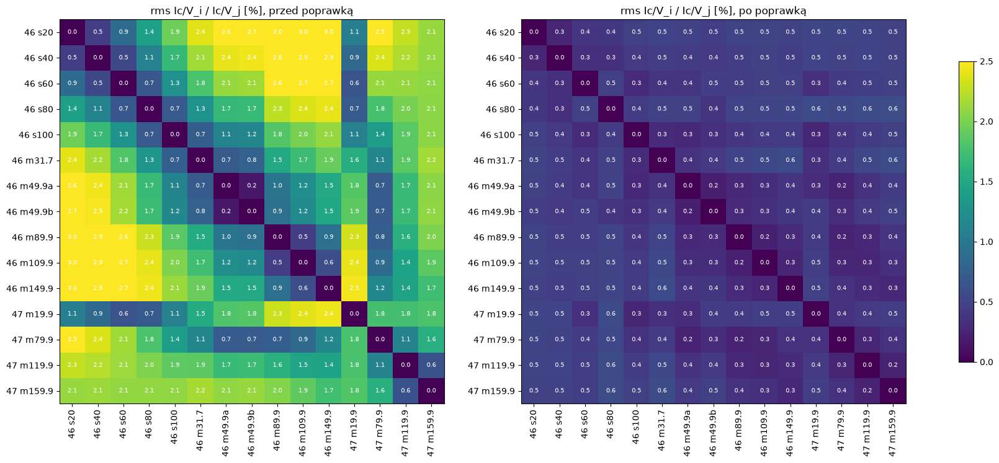

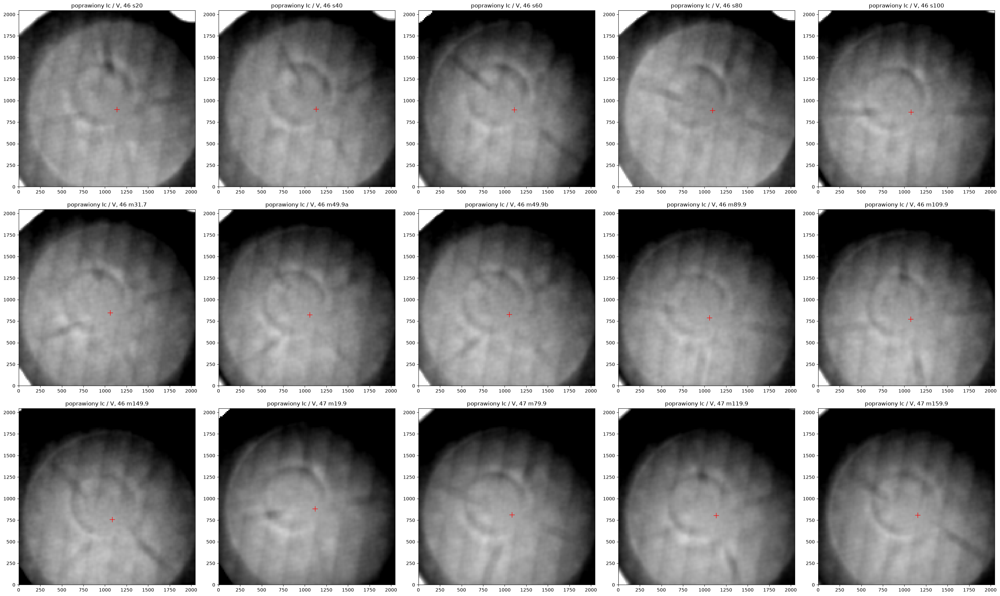

In [4]:
R_TEST = 700     # promień obszaru porównania [px]

near = np.hypot(xb - 1082, yb - 811) < R_TEST
labels = [d[0] for d in DOME_ALL]
mat = {}
for name, maps in (("przed", before), ("po", after)):
    m = np.zeros((len(labels), len(labels)))
    for i, a in enumerate(labels):
        for j, b in enumerate(labels):
            ratio = maps[a] / np.median(maps[a][near]) / (maps[b] / np.median(maps[b][near]))
            m[i, j] = 100 * np.std(gaussian_filter(ratio, 1)[near])
    mat[name] = m
    off = m[~np.eye(len(labels), dtype=bool)]
    print(f"{name}: rms między kątami - mediana {np.median(off):.2f} %, od {off.min():.2f} do {off.max():.2f} %")

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, name in zip(axes, ("przed", "po")):
    im = ax.imshow(mat[name], cmap="viridis", vmin=0, vmax=2.5)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_title(f"rms Ic/V_i / Ic/V_j [%], " + ("przed poprawką" if name == "przed" else "po poprawce"))
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{mat[name][i, j]:.1f}", ha="center", va="center", color="w", fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(30, 18))
for ax, label in zip(axes.ravel(), labels):
    ax.imshow(gaussian_filter(after[label] / np.median(after[label][near]), 1), origin="lower", cmap="gray", vmin=0.96, vmax=1.03, extent=[0, 2048, 0, 2048])
    ax.plot(*centres[label], "r+", ms=12)
    ax.set_title(f"poprawiony Ic / V, {label}")
plt.tight_layout()
plt.show()

### Co wyszło (2026-11-03)

- **Przepis działa na wszystkich kątach**: rms między parami kątów (Ic / V, r < 700 px) przed poprawką mediana 1.78 %
  (0.16-3.05 %), po poprawce mediana 0.43 % (0.21-0.59 %). Dwa flaty przy tym samym kącie (46 m49.9a, b) różnią się o
  0.2 % przed i po - to jest dno (szum, oświetlenie), więc z ghosta zostaje ~0.2-0.4 %.
- **Środek dziury przy każdym flacie inny**: w 1346 przesuwa się płynnie z kątem, łukiem od (1140, 900) przy s20 do
  (1082, 759) przy m149.9; w 1347 leży do ~70 px obok tego łuku (np. m119.9 (1136, 805) wobec m109.9 z 1346 (1071, 773)) -
  to ten skok z porównania nocy. Dopasowanie środka do każdego flatu go załatwia.
- **Co zostaje** (obrazki, skala 0.96-1.03, z różnicą kolorów S): pająk (proste pasy, obracają się z kątem) i łuk wewnątrz
  dziury (krawędź sierpa, też się obraca) - to, czego okrągły model z M = 4 nie odtworzy; do tego siatka V.
- Na wykresie macierzy (zapisanym przed poprawką kodu) tytuł prawej mówi "po poprawką" - powinno być "po poprawce".

## 15. To samo na flatach zmierzchowych (Ic i z)

Master flaty OFP (`processed-ofp/flats/`) - te, przez które OFP dzieli klatki naukowe. Zmierzchy, w których są V, Ic i z
(12 wieczorów, noce 1300-1345) oraz dwa poranki z V i z. `ROT-MECH` w starej skali (przed poprawką telemetrii w 1346), ale
kąt nie jest tu potrzebny - przepis dopasowuje wszystko do każdego flatu osobno. Kąty są różne: ~13, ~95-105, ~145-150,
~160-175.

Ghost w z ma też zewnętrzną krawędź: z / V po okręgu (1345 w) ma plateau ~1.04 od 450 do 750 px od środka dziury i
stromy spadek do ~0.97 między 850 a 950 px. Dlatego tu `R_END` = 1000 i model do 1100 px (w sekcji 14: 900 i 1000).

Przepis jak w sekcji 14, dla X = Ic i X = z: X / V -> środek dziury z cięć -> S (wielomian 2. stopnia z r < `R_HOLE` i
r > `R_END`) -> model po okręgu na X / V / S -> X / V / model. Model wygaszany łagodnie do 1 między `R_END` a `R_END` + `TAPER`
(tam ghosta z założenia nie ma) - bez tego na krawędzi modelu zostaje sztuczny okrąg.

Sprawdzian: flaty zmierzchowe mają jeszcze gradient nieba zmierzchu, inny w każdej sesji, więc przed porównaniem z każdej
mapy (przed i po poprawce) zdejmujemy wielomian 2. stopnia. Potem rms ilorazu map między sesjami, w r < `R_TEST`, jak w
sekcji 14.

Funkcje `design`, `poly_cols` i ustawienia modelu są tu powtórzone, żeby sekcja nie wymagała uruchamiania sekcji 14.

In [2]:
# (etykieta, V, Ic, z); w = wieczór, r = rano
TWILIGHT = [("1300 w", "zb08c_1300_45692", "zb08c_1300_45907", "zb08c_1300_45237"),
            ("1305 w", "zb08c_1305_46015", "zb08c_1305_46197", "zb08c_1305_45666"),
            ("1306 w", "zb08c_1306_45956", "zb08c_1306_46125", "zb08c_1306_45626"),
            ("1307 w", "zb08c_1307_45856", "zb08c_1307_46051", "zb08c_1307_45429"),
            ("1308 w", "zb08c_1308_45885", "zb08c_1308_46085", "zb08c_1308_45452"),
            ("1309 w", "zb08c_1309_45882", "zb08c_1309_46071", "zb08c_1309_45432"),
            ("1310 w", "zb08c_1310_45935", "zb08c_1310_46147", "zb08c_1310_45367"),
            ("1314 w", "zb08c_1314_46061", "zb08c_1314_46271", "zb08c_1314_45571"),
            ("1315 w", "zb08c_1315_46120", "zb08c_1315_46360", "zb08c_1315_45637"),
            ("1330 w", "zb08c_1330_46564", "zb08c_1330_46787", "zb08c_1330_46091"),
            ("1338 w", "zb08c_1338_46852", "zb08c_1338_47043", "zb08c_1338_46388"),
            ("1345 w", "zb08c_1345_47011", "zb08c_1345_46857", "zb08c_1345_46571"),
            ("1309 r", "zb08c_1309_92110", None, "zb08c_1309_92373"),
            ("1343 r", "zb08c_1343_89898", None, "zb08c_1343_90202")]
R_STEP, R_MAX, M_FIT, CLIP, MIN_COVER = 4, 1100, 4, 4, 0.5   # model po okręgu (sekcja 12); dalej niż w 14, bo z ma zewnętrzną krawędź ~900 px
R_HOLE, R_END, ORDER, EDGE = 340, 1000, 2, 64                # S (sekcja 13); R_END za zewnętrzną krawędzią ghosta w z
HALF = 25                                                    # cięcia (sekcja 10)
TAPER = 100                                                  # model wygaszany do 1 na TAPER px za R_END


def design(ph, m_max):
    # kolumny 1, cos(phi), sin(phi), ..., cos(m_max phi), sin(m_max phi)
    return np.column_stack([np.ones_like(ph)] + [f(m * ph) for m in range(1, m_max + 1) for f in (np.cos, np.sin)])


def poly_cols(x, y):
    # kolumny x^i y^j, i + j <= ORDER (x, y przeskalowane do -1..1)
    x, y = (x - 1024) / 1024, (y - 1024) / 1024
    return np.column_stack([x**i * y**j for i in range(ORDER + 1) for j in range(ORDER + 1 - i)])


def read_flat(flt, base):
    d = fits.getdata(f"{FLATS}/{flt}/{base}/{base}_master_f_{flt}.fits").astype(np.float64)
    return np.nan_to_num(d / np.nanmedian(d), nan=1.0)


yy, xx = np.mgrid[0:2048, 0:2048]
yb, xb = np.mgrid[0:128, 0:128] * 16 + 8
in_frame = (xb > EDGE) & (xb < 2048 - EDGE) & (yb > EDGE) & (yb < 2048 - EDGE)
r_mid = (np.arange(R_MAX // R_STEP) + 0.5) * R_STEP

tw_before, tw_after, tw_info = {"Ic": {}, "z": {}}, {"Ic": {}, "z": {}}, {"Ic": {}, "z": {}}
for label, b_v, b_ic, b_z in TWILIGHT:
    v = read_flat("V", b_v)
    for flt, base in (("Ic", b_ic), ("z", b_z)):
        if base is None:
            continue
        q = read_flat(flt, base) / v

        # środek dziury z cięć (sekcja 10)
        xc, yc = 1082, 811
        for it in range(3):
            cuts = {"lewo": q[yc - HALF:yc + HALF, :xc].mean(axis=0)[::-1], "prawo": q[yc - HALF:yc + HALF, xc:].mean(axis=0),
                    "dół": q[:yc, xc - HALF:xc + HALF].mean(axis=1)[::-1], "góra": q[yc:, xc - HALF:xc + HALF].mean(axis=1)}
            r50 = {}
            for name, p in cuts.items():
                p = gaussian_filter(p[:900], 5)
                i = 200 + np.argmax(np.gradient(gaussian_filter(p, 10))[200:650])
                lo, hi = np.median(p[i - 150:i - 50]), p[i:i + 200].max()
                r50[name] = i - 100 + np.argmax((p[i - 100:] - lo) / (hi - lo) > 0.5)
            xc, yc = xc + (r50["prawo"] - r50["lewo"]) // 2, yc + (r50["góra"] - r50["dół"]) // 2

        # S i model po okręgu (sekcje 13, 12)
        qb = blocks(q, 16)
        rb = np.hypot(xb - xc, yb - yc)
        use = in_frame & ((rb < R_HOLE) | (rb > R_END))
        c = np.linalg.lstsq(poly_cols(xb[use], yb[use]), qb[use], rcond=None)[0]
        g = q / (poly_cols(xx.ravel(), yy.ravel()) @ c).reshape(q.shape)
        rr = np.hypot(xx - xc, yy - yc)
        phi = np.arctan2(yy - yc, xx - xc)
        ring = (rr // R_STEP).astype(int)
        coef = np.full((len(r_mid), 2 * M_FIT + 1), np.nan)
        for k in range(len(r_mid)):
            idx = np.flatnonzero(ring == k)
            if len(idx) < MIN_COVER * 2 * np.pi * r_mid[k] * R_STEP:
                continue
            A, y = design(phi.flat[idx], M_FIT), g.flat[idx]
            cf = np.linalg.lstsq(A, y, rcond=None)[0]
            keep = np.abs(y - A @ cf) < CLIP * 1.4826 * np.median(np.abs(y - A @ cf))
            coef[k] = np.linalg.lstsq(A[keep], y[keep], rcond=None)[0]
        ok = np.isfinite(coef[:, 0])
        model = np.ones(q.shape)
        inside = rr <= r_mid[ok][-1]
        cols = design(phi[inside], M_FIT)
        model[inside] = sum(np.interp(rr[inside], r_mid[ok], coef[ok, j]) * cols[:, j] for j in range(2 * M_FIT + 1))
        model = 1 + (model - 1) * np.clip((R_END + TAPER - rr) / TAPER, 0, 1)   # łagodnie do 1 za R_END (tam ghosta nie ma)

        prof = coef[ok, 0]
        depth = np.median(prof[r_mid[ok] < R_HOLE]) / prof.max()          # dno dziury / grzbiet części okrągłej
        tw_before[flt][label], tw_after[flt][label] = qb, blocks(q / model, 16)
        tw_info[flt][label] = (xc, yc, depth)
        print(f"{flt:>2} {label}: środek ({xc}, {yc}), r50 {min(r50.values())}-{max(r50.values())} px, dziura / grzbiet {depth:.3f}, "
              f"model od {model.min():.3f} do {model.max():.3f}", flush=True)
        del q, g, rr, phi, ring, model, cols, inside
    del v

Ic 1300 w: środek (1038, 813), r50 418-473 px, dziura / grzbiet 0.950, model od 0.981 do 1.056


 z 1300 w: środek (927, 956), r50 365-382 px, dziura / grzbiet 0.915, model od 0.975 do 1.100


Ic 1305 w: środek (1217, 818), r50 233-302 px, dziura / grzbiet 0.988, model od 0.921 do 1.042


 z 1305 w: środek (927, 1001), r50 287-354 px, dziura / grzbiet 0.969, model od 0.985 do 1.045


Ic 1306 w: środek (1077, 921), r50 327-493 px, dziura / grzbiet 0.988, model od 0.975 do 1.030


 z 1306 w: środek (920, 958), r50 356-374 px, dziura / grzbiet 0.966, model od 0.983 do 1.044


... (16 outputs left out)

Ic 1345 w: środek (956, 943), r50 363-389 px, dziura / grzbiet 0.951, model od 0.984 do 1.057


 z 1345 w: środek (929, 953), r50 368-380 px, dziura / grzbiet 0.920, model od 0.975 do 1.095


 z 1309 r: środek (926, 947), r50 369-381 px, dziura / grzbiet 0.912, model od 0.973 do 1.106


 z 1343 r: środek (938, 1050), r50 362-382 px, dziura / grzbiet 0.922, model od 0.970 do 1.106


Macierze rms [%] między sesjami (po zdjęciu z każdej mapy wielomianu 2. stopnia), przed i po poprawce, osobno Ic / V
i z / V; pod spodem poprawione mapy.

Ic / V przed poprawką: rms między sesjami - mediana 0.63 %, od 0.04 do 2.22 %
Ic / V po poprawce: rms między sesjami - mediana 0.14 %, od 0.02 do 0.29 %


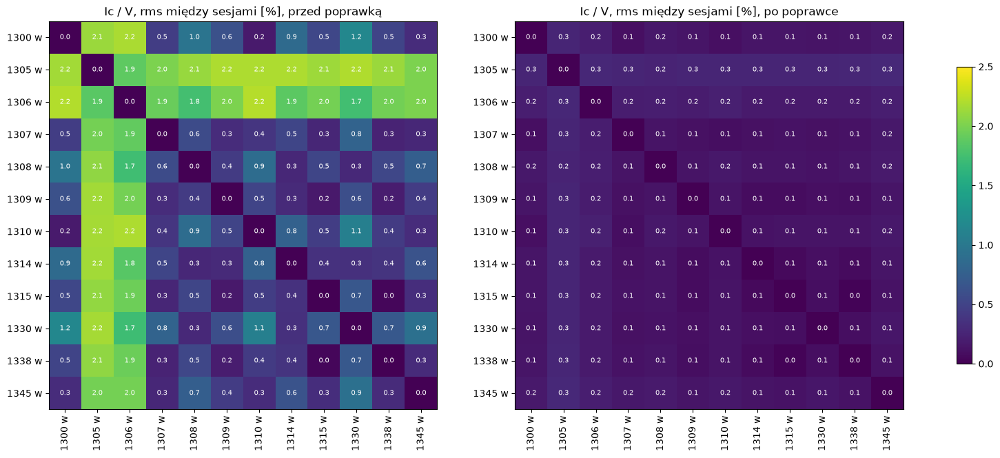

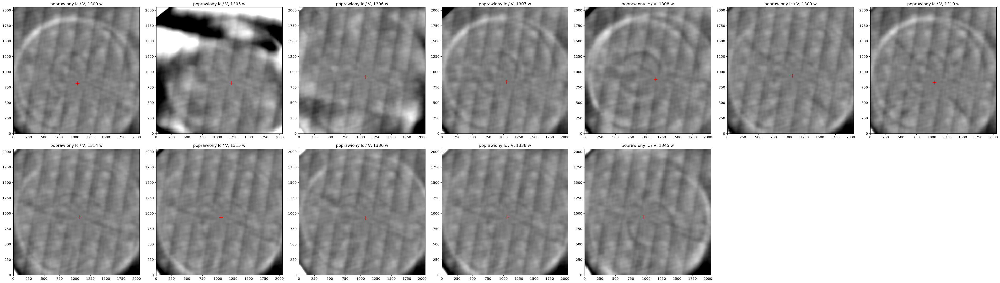

z / V przed poprawką: rms między sesjami - mediana 0.71 %, od 0.07 do 2.62 %
z / V po poprawce: rms między sesjami - mediana 0.16 %, od 0.05 do 0.23 %


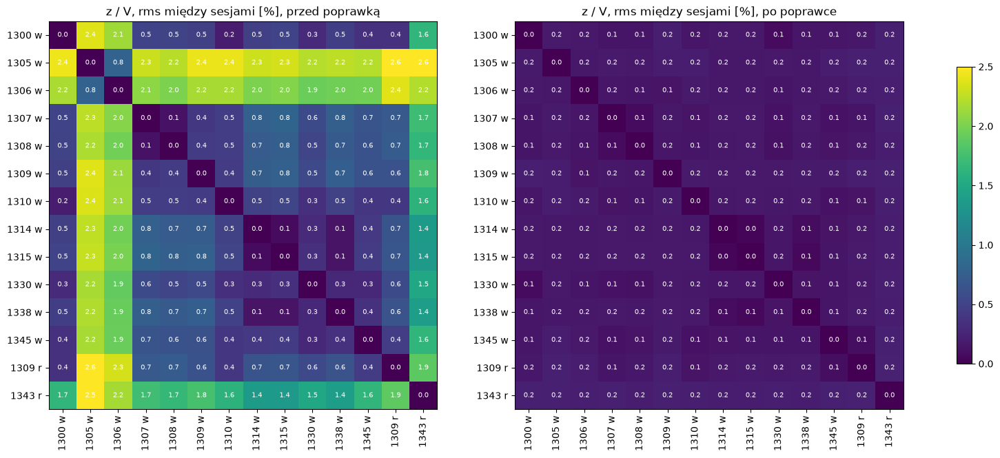

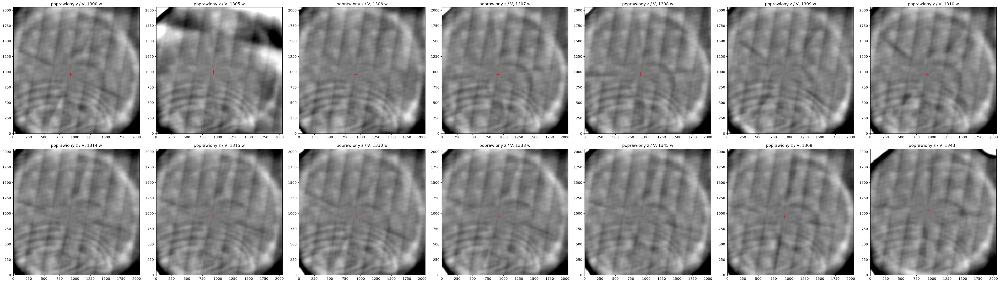

In [3]:
R_TEST = 700     # promień obszaru porównania [px]

near = np.hypot(xb - 1082, yb - 811) < R_TEST
fit = in_frame


def flatten(m):
    # mapa podzielona przez swój wielomian 2. stopnia (gradient zmierzchu)
    c = np.linalg.lstsq(poly_cols(xb[fit], yb[fit]), m[fit], rcond=None)[0]
    return m / (poly_cols(xb.ravel(), yb.ravel()) @ c).reshape(m.shape)


for flt in ("Ic", "z"):
    labels = list(tw_before[flt])
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for ax, (name, maps) in zip(axes, (("przed poprawką", tw_before[flt]), ("po poprawce", tw_after[flt]))):
        fm = {k: flatten(m) for k, m in maps.items()}
        mat = np.array([[100 * np.std(gaussian_filter(fm[a] / fm[b], 1)[near]) for b in labels] for a in labels])
        off = mat[~np.eye(len(labels), dtype=bool)]
        print(f"{flt} / V {name}: rms między sesjami - mediana {np.median(off):.2f} %, od {off.min():.2f} do {off.max():.2f} %")
        im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=2.5)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=90)
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels)
        ax.set_title(f"{flt} / V, rms między sesjami [%], {name}")
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{mat[i, j]:.1f}", ha="center", va="center", color="w", fontsize=7)
    fig.colorbar(im, ax=axes, shrink=0.7)
    plt.show()

    fig, axes = plt.subplots(2, 7, figsize=(42, 12))
    for ax, label in zip(axes.ravel(), labels):
        m = flatten(tw_after[flt][label])
        ax.imshow(gaussian_filter(m, 1), origin="lower", cmap="gray", vmin=0.98, vmax=1.02, extent=[0, 2048, 0, 2048])
        ax.plot(*tw_info[flt][label][:2], "r+", ms=12)
        ax.set_title(f"poprawiony {flt} / V, {label}")
    for ax in axes.ravel()[len(labels):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Co wyszło (2026-11-03)

- **Na flatach zmierzchowych przepis też działa**: rms między sesjami (po zdjęciu wielomianu 2. stopnia, r < 700 px)
  Ic / V 0.63 % -> 0.14 % (mediana; max 2.22 -> 0.29 %), z / V 0.71 % -> 0.16 % (max 2.62 -> 0.23 %).
- **Ghost w z jest szerokim pierścieniem z dwiema krawędziami**: wewnętrzna r50 ~365-390 px, zewnętrzna ~850-950 px
  (z / V po okręgu: dno ~0.96-0.98, plateau ~1.04 od 450 do 750 px, spadek do ~0.97 przy 950 px). Dziura / grzbiet 0.92
  (0.97 w 1305 i 1306 - słabszy ghost). Pierwsza wersja z `R_END` = 900 zostawiała jasny okrąg przy ~950 px - stąd 1000.
- **Środek ghosta w z prawie stały**: ~(905-938, 947-964) we wszystkich sesjach, choć kąty są od ~13 do ~178 (poza 1305 w
  (927, 1001) i 1343 r (938, 1050)). Inny niż w Ic (dome ~(1050-1150, 760-900)) - ghost z i Ic to nie ten sam obraz w tym
  samym miejscu.
- **W Ic środek z cięć jest niepewny**: r50 w czterech kierunkach różnią się o ~100-170 px (zmierzchowy ghost Ic jest słabszy
  i mniej ostry), środki skaczą (956-1217, 813-943). Tam, gdzie środek wyszedł daleko od ~(1053, 937) (1300, 1307, 1308,
  1310), po poprawce zostaje jasny łuk przy ~950 px i ślad krawędzi wewnętrznej. Do poprawy: środek z dopasowania okręgu do
  całej krawędzi zamiast czterech cięć.
- **1305 w** (i słabiej 1306 w) ma dużą strukturę w lewym górnym rogu w obu filtrach - zły zmierzch (chmury?); do wyrzucenia.
- **Co zostaje w z** (wszystkie sesje tak samo): pająk, siatka V i koncentryczne łuki w dolnej połowie klatki - te same w
  każdej sesji, więc to raczej struktura flatu z (grubość krzemu / fringing), nie ghost.

## 16. Czy poprawka ghosta poprawia fotometrię? Te same gwiazdy, co w sekcji 9

Dane z sekcji 9 (`~/data/ghost/zb08_<filtr>_samestar.parquet`): reszty tych samych gwiazd na różnych nocach, gdy lądują w
różnych miejscach detektora. W sekcji 9 regresorem była cała różnica flatów z / r (P) - a w niej jest nie tylko ghost.
Tu regresorem jest **sam model ghosta** G (jak w sekcji 15, z jednego flatu zmierzchowego: z - wieczór 1345, Ic - wieczór
1338, gdzie środek z cięć wyszedł dobrze; ghost w z ma środek prawie stały, więc jeden model wystarczy na wszystkie noce).

- Gm = 2.5 log10 G w miejscu gwiazdy [mag], Gc = Gm - średnie Gm tej gwiazdy.
- Jeśli ghost we flacie to tylko dodane światło (nieprawdziwe dla gwiazd), flat z ghostem robi gwiazdę na pierścieniu za
  słabą o Gm: nachylenie reszty względem Gc = **1**. Jeśli ghost byłby prawdziwą czułością: **0**.
- Poprawka: flat / G, czyli mag - Gm; punkty zerowe klatek i średnie gwiazd liczone od nowa (jak w `samestar_phot.py`).
- Kontrola: r z modelem ghosta z (w r ghosta nie ma) - nachylenie powinno być 0.

Używa `design`, `poly_cols`, `read_flat` i ustawień z sekcji 15.

In [4]:
GHOST_FROM = {"z": ("zb08c_1345_47011", "zb08c_1345_46571"), "Ic": ("zb08c_1338_46852", "zb08c_1338_47043")}   # (V, flat) - model ghosta

G_blocks = {}
for flt, (b_v, b_x) in GHOST_FROM.items():
    q = read_flat(flt, b_x) / read_flat("V", b_v)
    xc, yc = 1082, 811
    for it in range(3):
        cuts = {"lewo": q[yc - HALF:yc + HALF, :xc].mean(axis=0)[::-1], "prawo": q[yc - HALF:yc + HALF, xc:].mean(axis=0),
                "dół": q[:yc, xc - HALF:xc + HALF].mean(axis=1)[::-1], "góra": q[yc:, xc - HALF:xc + HALF].mean(axis=1)}
        r50 = {}
        for name, p in cuts.items():
            p = gaussian_filter(p[:900], 5)
            i = 200 + np.argmax(np.gradient(gaussian_filter(p, 10))[200:650])
            lo, hi = np.median(p[i - 150:i - 50]), p[i:i + 200].max()
            r50[name] = i - 100 + np.argmax((p[i - 100:] - lo) / (hi - lo) > 0.5)
        xc, yc = xc + (r50["prawo"] - r50["lewo"]) // 2, yc + (r50["góra"] - r50["dół"]) // 2
    qb = blocks(q, 16)
    rb = np.hypot(xb - xc, yb - yc)
    use = in_frame & ((rb < R_HOLE) | (rb > R_END))
    c = np.linalg.lstsq(poly_cols(xb[use], yb[use]), qb[use], rcond=None)[0]
    g = q / (poly_cols(xx.ravel(), yy.ravel()) @ c).reshape(q.shape)
    rr = np.hypot(xx - xc, yy - yc)
    phi = np.arctan2(yy - yc, xx - xc)
    ring = (rr // R_STEP).astype(int)
    coef = np.full((len(r_mid), 2 * M_FIT + 1), np.nan)
    for k in range(len(r_mid)):
        idx = np.flatnonzero(ring == k)
        if len(idx) < MIN_COVER * 2 * np.pi * r_mid[k] * R_STEP:
            continue
        A, y = design(phi.flat[idx], M_FIT), g.flat[idx]
        cf = np.linalg.lstsq(A, y, rcond=None)[0]
        keep = np.abs(y - A @ cf) < CLIP * 1.4826 * np.median(np.abs(y - A @ cf))
        coef[k] = np.linalg.lstsq(A[keep], y[keep], rcond=None)[0]
    ok = np.isfinite(coef[:, 0])
    model = np.ones(q.shape)
    inside = rr <= r_mid[ok][-1]
    cols = design(phi[inside], M_FIT)
    model[inside] = sum(np.interp(rr[inside], r_mid[ok], coef[ok, j]) * cols[:, j] for j in range(2 * M_FIT + 1))
    model = 1 + (model - 1) * np.clip((R_END + TAPER - rr) / TAPER, 0, 1)
    G_blocks[flt] = blocks(model, 16)
    print(f"G {flt}: środek ({xc}, {yc}), od {model.min():.3f} do {model.max():.3f}")
    del q, g, rr, phi, ring, model, cols, inside

G z: środek (929, 953), od 0.975 do 1.095


G Ic: środek (1053, 938), od 0.985 do 1.054


Nachylenie reszty względem Gc (bootstrap po polach), rms reszt przed i po poprawce, i reszty w przedziałach Gc.

 z (G z z): nachylenie 0.89 ± 0.08, rms reszt 29.3 -> 27.2 mmag, przy |Gc| > 1 %: 35.0 -> 29.2 mmag (9030 z 53317 pomiarów)


Ic (G z Ic): nachylenie 0.96 ± 0.08, rms reszt 31.3 -> 29.9 mmag, przy |Gc| > 1 %: 36.0 -> 32.0 mmag (6819 z 62764 pomiarów)


 r (G z z): nachylenie 0.02 ± 0.02, rms reszt 27.9 -> 28.1 mmag, przy |Gc| > 1 %: 31.4 -> 37.3 mmag (15558 z 132566 pomiarów)


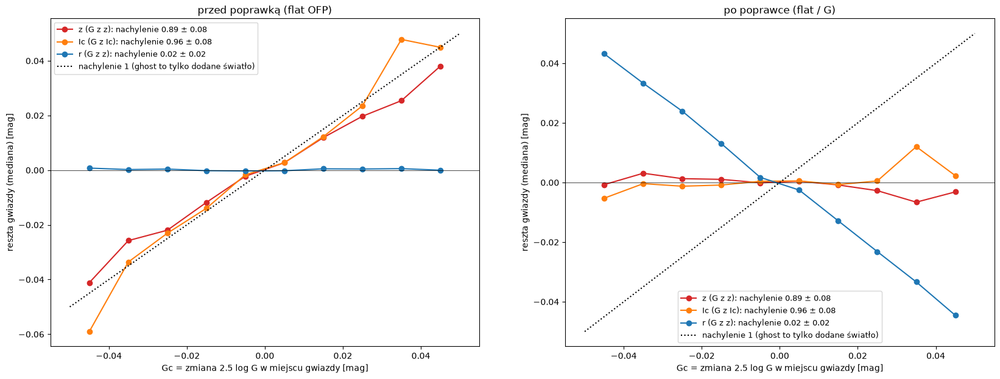

In [5]:
N_BOOT = 200
bins = np.linspace(-0.05, 0.05, 11)


def zp_and_means(c, mag):
    # punkty zerowe klatek i średnie gwiazd na zmianę, jak w samestar_phot.py; zwraca reszty
    for _ in range(3):
        zp = (mag - mag.groupby(c.key).transform("mean")).groupby(c.frame).transform("median")
        m0 = (mag - zp).groupby(c.key).transform("mean")
    return mag - zp - m0


fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for flt, g_from, color in [("z", "z", "C3"), ("Ic", "Ic", "C1"), ("r", "z", "C0")]:
    c = pd.read_parquet(os.path.expanduser(f"~/data/ghost/zb08_{flt}_samestar.parquet"))
    G = G_blocks[g_from]
    c["Gm"] = 2.5 * np.log10(G[np.clip((c.y / 16).astype(int), 0, 127), np.clip((c.x / 16).astype(int), 0, 127)])
    c["Gc"] = c.Gm - c.groupby("key").Gm.transform("mean")
    c["res_after"] = zp_and_means(c, c.mag - c.Gm)
    k = np.polyfit(c.Gc, c.res, 1)[0]
    rng = np.random.default_rng(1)
    objs = c.obj.unique()
    ks = [np.polyfit(s.Gc, s.res, 1)[0] for s in (c[c.obj.isin(rng.choice(objs, len(objs)))] for _ in range(N_BOOT))]
    big = np.abs(c.Gc) > 0.01                   # pomiary, przy których gwiazda przesunęła się o > 1 % ghosta
    print(f"{flt:>2} (G z {g_from}): nachylenie {k:.2f} ± {np.std(ks):.2f}, rms reszt {1000 * c.res.std():.1f} -> {1000 * c.res_after.std():.1f} mmag, "
          f"przy |Gc| > 1 %: {1000 * c.res[big].std():.1f} -> {1000 * c.res_after[big].std():.1f} mmag ({big.sum()} z {len(c)} pomiarów)")
    lab = f"{flt} (G z {g_from}): nachylenie {k:.2f} ± {np.std(ks):.2f}"
    for ax, col in zip(axes, ("res", "res_after")):
        m = c.groupby(pd.cut(c.Gc, bins), observed=True)[col].median()
        ax.plot([iv.mid for iv in m.index], m.values, "o-", color=color, label=lab)
for ax, title in zip(axes, ("przed poprawką (flat OFP)", "po poprawce (flat / G)")):
    ax.plot(bins, bins, "k:", label="nachylenie 1 (ghost to tylko dodane światło)")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("Gc = zmiana 2.5 log G w miejscu gwiazdy [mag]")
    ax.set_ylabel("reszta gwiazdy (mediana) [mag]")
    ax.set_title(title)
    ax.legend(fontsize=9)
plt.show()

### Co wyszło (2026-11-03)

- **Ghost jest (prawie) w całości dodanym światłem**: nachylenie reszt gwiazd względem samego modelu ghosta z 0.89 ± 0.08,
  Ic 0.96 ± 0.08; kontrola r (model z, w r ghosta nie ma) 0.02 ± 0.02. Dawne k z sekcji 9 (z 0.53, Ic 0.22) było zaniżone,
  bo regresor P = log(flat_z / flat_r) zawiera też prawdziwe różnice flatów (k = 0), nie tylko ghosta.
- **Wniosek: flat trzeba podzielić przez cały model ghosta.** Po poprawce reszty nie zależą już od Gc (prawy wykres:
  z i Ic płasko w ±0.005 mag).
- **Rozrzut fotometrii spada**: rms reszt z 29.3 -> 27.2 mmag (wszystkie pomiary), 35.0 -> 29.2 mmag tam, gdzie gwiazda
  przesunęła się o > 1 % ghosta (17 % pomiarów); Ic 31.3 -> 29.9 i 36.0 -> 32.0 mmag. Kontrola r z (niepotrzebną) poprawką
  się psuje (31.4 -> 37.3 mmag) - poprawka działa tylko tam, gdzie ghost jest.
- **Skala błędu OFP**: model ghosta w z od 0.975 do 1.095, czyli gwiazda na grzbiecie pierścienia wobec gwiazdy w dziurze
  różni się o ~0.12 mag (Ic: 0.985-1.054, ~0.07 mag). Przy zwykłych przesunięciach pola między nocami to kilka procent
  (wykres: do ±0.04 mag przy |Gc| ~0.045).
- Jeden model z (wieczór 1345) wystarczył na noce 1290-1345, bo ghost w z ma prawie stały środek i kształt.

## Co znalazłem (2026-11-01)

**1. Fringing w Ic, i, z - główne znalezisko.**
- Niebo nocne ma szerokie, poziomicowe prążki (jak mapa warstwicowa), szerokości ~100-200 px. To interferencja światła w
  cienkiej warstwie krzemu detektora: w czerwieni krzem jest częściowo przezroczysty, światło odbija się od jego
  powierzchni i interferuje. Prążki to „warstwice” grubości detektora.
- Najsilniejsze w z, słabsze w Ic, najsłabsze w i. Rms prążków w `_zdf` (po odjęciu dużej skali): z ~2.4 % nieba,
  Ic ~1.7 %, i ≤ 1.7 % (przy niskim niebie w i ta liczba zawiera też szum, więc to górna granica).
- **Redukcja ich nie usuwa**: są w surowej klatce i w `_zdf` tak samo. Flat ich nie zawiera - flaty zmierzchowe mają
  widmo ciągłe, a prążki pochodzą głównie od wąskich linii emisyjnych nocnego nieba (OH), dla których interferencja ma
  duży kontrast.
- Wzór jest **stały**: ten sam na różnych polach i w różne noce (korelacja 0.6-0.8; resztę psują gwiazdy i szum). Związany
  z detektorem, a nie z niebem.
- Prążki są **addytywne** (dodatkowe światło nieba), więc zwykle usuwa się je klatką prążków (fringe frame): mediana wielu
  klatek nieba w danym filtrze, bez gwiazd, odejmowana od każdej klatki ze skalą dobraną do jej nieba. OFP tego nie robi.
- Wpływ na fotometrię: lokalne tło wokół gwiazdy w większości je zbiera (prążki są szerokie), ale dla słabych gwiazd na
  zboczu prążka i dla dużych aperturek błąd tła może sięgać ~1-2 % nieba.

**2. Obwarzanek (ghost pupil) w Ic, i, z - sekcje 1, 4, 5, 6.**
- To, co wyglądało jak „ciemny dysk”, jest dziurą jasnego, szerokiego pierścienia: obraz źrenicy teleskopu z zasłonięciem
  centralnym i ramionami pająka, odbity (okno kamery / filtr) - hipoteza ghost pupil. Głębokość dziury względem
  pierścienia: z ~6 % (flaty), Ic ~3 %, i ~0.7 %; w B, V, g, r brak.
- **Obraca się i przesuwa z rotatorem** (sekcja 6): różnice flatów o różnym `ROT-MECH` pokazują pary jasny-ciemny na
  krawędziach pierścienia i na czterech ramionach pająka. Przy 20° różnicy (ROT 170 - 150) widać wprost cztery szprychy;
  przy większych różnicach przesuwają się całe pierścienie, więc środek ghosta nie leży na osi obrotu (decentracja).
  Detektor (flat, prążki fringingu) jest nieruchomy, ghost się rusza - to jest dźwignia do ich rozdzielenia.
- **Siła zależy od światła** (sekcja 5): flaty zmierzchowe 0.930-0.944 (bardzo stabilnie), ciemne niebo bez Księżyca
  ~0.92 (dziura głębsza), niebo z jasnym, wysokim Księżycem 0.96-1.0 (obwarzanka prawie nie ma). Trzy nietypowe flaty
  (0.975-0.988) to flaty wieczorne przy wysokim, jasnym Księżycu (1305, 1306) i jeden poranny (1299).
- **Skutek dla `_zdf`**: flat ma jedną, stałą siłę ghosta, więc bez Księżyca środek nieba zostaje ~1 % ciemniejszy, a przy
  jasnym Księżycu **4-6 % jaśniejszy** - flat w tych klatkach pogarsza niebo.
- Czy ghost dotyczy też gwiazd (addytywny vs multiplikatywny) - jeszcze nie sprawdzone. Jeśli addytywny, dzielenie przez
  flat z ghostem fałszywie skaluje jasności gwiazd w obwarzanku o kilka procent w z.
- FFT (sekcja 4): obwarzanek ma ~1800 px, więc w widmie siedzi w kilku najniższych pikselach; we flacie widać jego
  koncentryczne pierścienie, na polu gwiazd ginie pod gwiazdami i prążkami. Sama FFT go nie wyizoluje.

**3. Rozdzielenie flatu i ghosta (sekcje 7-8).**
- **Przez obrót - tylko częściowo.** Model „flat przypięty do detektora + ghost obracany z ROT-MECH wokół osi + płaszczyzna”
  zmniejsza resztę flatów z 0.0183 do 0.0070. Oś wyszła w (1096, 968) px. W G (część, która się obraca) są ramiona pająka
  i asymetria pierścienia. Ale **sam obwarzanek zostaje w F**: leży blisko osi, więc jego okrągła część przy obrocie się nie
  zmienia. Flaty z ROT ~5 i ~100 model tłumaczy słabo (reszta 0.007-0.017, z wyraźną strukturą) - czysty obrót wokół jednej
  osi to za mało.
- **Przy jasnym Księżycu obwarzanek znika z nieba** - flat minus takie niebo wygląda jak czysty obwarzanek (jasny pierścień
  ~+5 % z ciemniejszą dziurą, ~(1000, 1000)), prawie taki sam przy ROT ~5 i ~170: **obwarzanek jest przypięty do kamery**,
  z rotatorem obraca się tylko drobna struktura (pająk) - pasuje do odbicia od okna / filtra.
- **Ale dlaczego znika - poprawka.** Nie decyduje widmo (zmierzch i Księżyc mają prawie to samo widmo, a dają 0.94 i 0.99)
  ani faza Księżyca (korelacja głębokości z oświetleniem tarczy 0.13), tylko **wysokość Księżyca** (korelacja 0.79; wszystkie
  klatki bez obwarzanka mają Księżyc > 55°). Trzy nietypowe flaty były skierowane **w stronę Słońca** (wieczorem az 243°
  i 284°, rano az 115°), a zwykłe są od Słońca. Hipoteza: jasne źródło poza polem (wysoki Księżyc, jasny horyzont) daje
  światło rozproszone w kopule / tubusie, które nie przechodzi przez źrenicę, nie robi obwarzanka i go rozcieńcza.
  Jeśli tak, **niebo przy wysokim Księżycu nie jest czystym flatem bez ghosta** (to niebo + światło rozproszone).

**4. Ghost jest (w dużej części) addytywny - flat OFP psuje fotometrię gwiazd w z (sekcja 9).**
- Te same gwiazdy w różnych miejscach detektora: reszta rośnie monotonicznie ze zmianą flat_z / flat_r. Nachylenie
  **k = 0.53 ± 0.11 w z** (4538 gwiazd, 76 pól), **0.22 ± 0.11 w Ic** (obwarzanek ~2x słabszy - pasuje), **0.03 ± 0.02 w r**
  (test kontrolny: brak trendu).
- Czyli ok. połowa wielkoskalowej różnicy flatu z od flatu r nie dotyczy gwiazd - to światło dodane (ghost), a dzielenie
  przez nie zaniża jasności gwiazd w pierścieniu. Reszta różnicy (k < 1) to prawdopodobnie prawdziwe różnice czułości z vs r.
- Skala błędu: P zmienia się na detektorze o ~0.06 mag, więc gwiazdy w z mają błędy zależne od położenia rzędu ±1.5 %
  (~0.03 mag między pierścieniem a dziurą / brzegiem).
- Zastrzeżenia: P z flatów jednej nocy; dźwignia mała (gwiazdy przesuwają się o 100-250 px); możliwe wpływy zmian PSF
  w polu (w r ich nie widać).

**Przy okazji (poza czerwienią)**
- Flaty V i r mają regularną siatkę „rombów” co ~250-285 px (słabo też i); w widmie flatu r to regularna siatka kropek
  (sekcja 4). Skąd - nie wiem.
- Wcześniej (`fft_fields.ipynb`, RR Cet w V) siatka słabych jasnych punktów co ~10 px.
- Jasna plama przy (150, 1250) na mapach BK Tuc to nasycona jasna gwiazda z halo, a nie ghost.

**Do zrobienia, jeśli chcemy iść dalej**
- Sprawdzić hipotezę światła rozproszonego: nadwyżka jasności nieba przy wysokim Księżycu, związek z `DOME-AZ`, kształt
  tego światła; flaty w z w stronę Słońca i od Słońca jednego wieczoru.
- Model z siłą ghosta zmienną od klatki: flat_k = F + a_k · G (a_k z głębokości dziury), z F z nieba przy Księżycu.
- Czy ghost dotyczy gwiazd: fotometria tej samej gwiazdy w obwarzanku i poza nim.
- Dlaczego Księżyc osłabia obwarzanek (wysokość Księżyca, odległość od pola?).
- Klatka prążków (fringing) dla z i Ic.